# SFOLS: Optimistic Linear Support with Successor Features

In [1]:
import heapq
import itertools
import random

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import linprog
import mo_gymnasium as mo_gym

np.set_printoptions(suppress=True, precision=3)

env = mo_gym.make("deep-sea-treasure-v0")
core = env.unwrapped
GAMMA = 0.99
N_ACTIONS = core.action_space.n
FEAT_DIM = 2
START_STATE = (0, 0)

ground_truth_ccs = np.array(core.pareto_front(gamma=GAMMA))
print(f"{N_ACTIONS} actions, {FEAT_DIM} objectives, ground-truth CCS has {len(ground_truth_ccs)} points.")

4 actions, 2 objectives, ground-truth CCS has 10 points.


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gymnasium/spaces/box.py:297: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


## 1. Representing a policy by its SF, and combining policies via GPI


In [2]:
class SFTable:
    """Tabular successor-feature table: state -> (num_actions, feat_dim) array."""

    def __init__(self, num_actions, feat_dim, default_vec):
        self.default_vec = default_vec  # (num_actions, feat_dim), used for any never-visited state
        self.table = {}

    def __getitem__(self, state):
        if state not in self.table:
            self.table[state] = self.default_vec.copy()
        return self.table[state]


def gpi_action(rng, state, w, sf_tables):
    """argmax_a max_i psi_i(state, a) . w, breaking ties uniformly at random.

    Random tie-breaking matters a lot here: with optimistic initialization, many
    (state, action) pairs start out exactly tied. `np.argmax` breaks ties by always
    picking the first (lowest) index, which silently collapses exploration into a
    single repeated action instead of trying each tied action in turn.
    """
    values = np.stack([sft[state] @ w for sft in sf_tables], axis=0)  # (n_tables, A)
    action_values = values.max(axis=0)  # (A,) -- best over tables, per action
    max_val = action_values.max()
    candidates = np.flatnonzero(np.isclose(action_values, max_val))
    return int(rng.choice(candidates))

## 2. `solve_task`: learning one policy's SF (Algorithm 1, line 7 / Algorithm 4)


**Early stopping, added after noticing where `sfols`'s "more iterations than `|CCS|`" gap actually comes from:** `psi` starts from an optimistic upper bound (`optimistic_vec`), so Q-learning only ever corrects it *downward* -- the achieved start-state value decreases monotonically and then plateaus once training has converged. Checked empirically: a weight whose true optimum turns out to already be a known policy plateaus in as little as 20-50k steps, while a weight that needs a genuinely new policy still takes closer to the full 100k. `solve_task` now checks the achieved value every `check_interval` steps and stops as soon as it has moved by less than `plateau_tol` for `patience` consecutive checks, instead of always running to `num_steps`. This needs no oracle and doesn't change *which* weights get explored or *what* they converge to (validated against fixed-budget runs) -- it just stops paying for steps once the answer is already in, which is most of the savings for exactly the "turns out not new" corners.

In [ ]:
def solve_task(env, w, num_steps=100_000, alpha=0.1, gamma=GAMMA,
               eps_start=1.0, eps_end=0.05, optimistic_vec=(25.0, 0.0), seed=0,
               check_interval=2000, patience=3, plateau_tol=0.01):
    """Learn a tabular SF psi(s,a) for a single scalarized task r.w, via optimistic
    tabular TD-learning. optimistic_vec must upper-bound the true SF in every
    component so unvisited (state, action) pairs always look promising.

    num_steps is a CAP, not a target: because psi starts optimistic and Q-learning
    only ever corrects it downward, the achieved start-state value decreases
    monotonically and then plateaus once learning has converged -- checked every
    check_interval steps, training stops as soon as that value has moved by less
    than plateau_tol for `patience` consecutive checks. This needs no oracle and no
    knowledge of which weight this is: it just detects "more steps won't change the
    answer" and stops paying for them. Empirically this is where most of `sfols`'s
    "more iterations than |CCS|" gap actually goes -- weights whose true optimum
    turns out to already be a known policy plateau in ~20-50k steps instead of
    burning the full 100k, while weights that need genuine training still get
    however many steps they actually require."""
    rng = random.Random(seed)
    default_vec = np.tile(np.array(optimistic_vec), (N_ACTIONS, 1))
    psi = SFTable(N_ACTIONS, FEAT_DIM, default_vec)

    obs, _ = env.reset(seed=seed)
    state = tuple(int(x) for x in obs)
    last_v, streak = None, 0
    for t in range(num_steps):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / (num_steps))
        if rng.random() < eps:
            action = rng.randrange(N_ACTIONS)
        else:
            action = gpi_action(rng, state, w, [psi])

        next_obs, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(int(x) for x in next_obs)

        if terminated:
            target = phi
        else:
            a_prime = gpi_action(rng, next_state, w, [psi])
            target = phi + gamma * psi[next_state][a_prime]
        psi[state][action] += alpha * (target - psi[state][action])

        if terminated or truncated:
            obs, _ = env.reset()
            state = tuple(int(x) for x in obs)
        else:
            state = next_state

        if (t + 1) % check_interval == 0:
            v = float((psi[START_STATE] @ w).max())
            if last_v is not None and abs(v - last_v) < plateau_tol:
                streak += 1
                if streak >= patience:
                    break
            else:
                streak = 0
            last_v = v
    return psi


def expected_sf(psi_table, w, start_state=START_STATE):
    """psi^pi (Section 2.2): the SF of the greedy action at the start state."""
    values = psi_table[start_state] @ w
    return psi_table[start_state][np.argmax(values)].copy()

# sanity check against notebook 1: w=[1,0] should reach the deepest treasure (23.7)
psi_test = solve_task(env, np.array([1.0, 0.0]), num_steps=100_000, seed=1)
print("psi^pi for w=[1,0]:", expected_sf(psi_test, np.array([1.0, 0.0])))
print("(ground truth for this weight:", ground_truth_ccs[np.argmax(ground_truth_ccs[:, 0])], ")")


## 3. Corner weights (Section 4, Theorem 4.1)


In [4]:
def v_smp(psi_vecs, w):
    """v^SMP_w = max_i psi_i . w (Eq. 15). -inf when nothing has been learned yet."""
    if not psi_vecs:
        return -np.inf
    return max(v @ w for v in psi_vecs)


def corner_weights_2d(psi_vecs, n_grid=2000):
    """All w0 in [0,1] where argmax_i psi_i . [w0, 1-w0] changes."""
    w0_grid = np.linspace(0.0, 1.0, n_grid)
    weights = np.stack([w0_grid, 1 - w0_grid], axis=1)
    values_per_policy = weights @ np.array(psi_vecs).T
    best_policy = values_per_policy.argmax(axis=1)
    switch_idx = np.where(np.diff(best_policy) != 0)[0]
    return [np.array([w0, 1 - w0]) for w0 in w0_grid[switch_idx]]


# quick check: 2 policies (the segment endpoints) should give exactly 1 corner weight
demo_psi = [ground_truth_ccs[0], ground_truth_ccs[-1]]
print("Corner weight between the cheapest and priciest treasure:", corner_weights_2d(demo_psi))

Corner weight between the cheapest and priciest treasure: [array([0.462, 0.538])]


## 4. `EstimateImprovement` (Algorithm 2)


In [5]:
def estimate_improvement(w, psi_vecs, w_exp):
    """Delta(w) = v_bar*_w - v^SMP_w, via the LP in Algorithm 2."""
    if not w_exp:
        return np.inf  # nothing constrains the bound yet -> unbounded potential
    d = len(w)
    A_ub = np.array([w_prime for w_prime in w_exp])
    b_ub = np.array([v_smp(psi_vecs, w_prime) for w_prime in w_exp])
    res = linprog(c=-np.array(w), A_ub=A_ub, b_ub=b_ub, bounds=[(None, None)] * d, method="highs")
    v_bar = -res.fun if res.success else np.inf
    return v_bar - v_smp(psi_vecs, w)


# sanity check: with only the two segment endpoints solved, the improvement estimate
# at their exact corner weight should be strictly positive (there's a real gap to close)
w_corner = corner_weights_2d(demo_psi)[0]
print("Delta at the one corner weight:", estimate_improvement(w_corner, demo_psi, [np.array([1.0, 0.0]), np.array([0.0, 1.0])]))

Delta at the one corner weight: 8.808890436766786


## 5. The main loop (Algorithm 1)

A priority queue of candidate weights, seeded with the simplex extrema at "infinite" priority (must-solve, since we have no data yet to estimate their priority from). Each iteration: pop the highest-priority weight, solve it, and if it yields a genuinely new SF, prune now-redundant queued weights, compute the new corner weights, and push them with their `EstimateImprovement` priority.

**One bug worth flagging, found by running this, not by reading the pseudocode carefully enough the first time:** line 10 of Algorithm 1 removes queued weights `w'` where the new policy already beats `v^SMP_{w'}` — but `v^SMP_{w'}` over an *empty* `Psi` is `-inf` by definition (Eq. 15), so literally anything "beats" it. Applied naively, this wipes out the *other* still-unprocessed simplex extremum the very first time any policy is found, before it's ever been solved. The extrema were put in the queue with infinite priority specifically to force them to be solved regardless of what any improvement estimate says — so we exempt anything still carrying that forced/infinite priority from this pruning step, and only prune entries whose priority came from a genuine (finite) `EstimateImprovement` call.

We stop when the queue empties or every remaining priority drops below a small tolerance (an ε-CCS, Definition 3.3/footnote 3), whichever comes first.

**A second inefficiency, found by actually running this and watching iterations blow past `|CCS|`:** every time a new policy is found, *every* corner weight of the current envelope is recomputed from scratch and unconditionally pushed onto the queue -- including weights that were already sitting there, untouched by the new policy, with an already-correct priority. Left as-is, duplicate copies of the same weight pile up (e.g. weight `[0.391, 0.609]` got pushed four times across iterations 3, 4, 6, and 9 before it was ever popped once), and each duplicate is later popped and fully re-solved -- another `num_steps_per_task` of Q-learning -- only to rediscover the exact same, already-known policy. That's the main source of "more iterations than `|CCS|`": not new weights turning out to map to old policies, but the *same* weight being solved several times over. The fix is the standard priority-queue "decrease-key": key the queue by (rounded) weight so each weight holds at most one live entry -- pushing an already-queued weight retires the stale entry (lazy deletion) instead of adding a second copy. It doesn't change which policies get found, only how many redundant solves it takes to find them.

In [ ]:
def sfols(env, num_objectives=2, num_steps_per_task=100_000, max_iterations=25,
          tol=1e-2, seed=0, verbose=True):
    Psi, Pi, W_exp = [], [], []
    counter = itertools.count()
    Q = []       # heap of [neg_priority, tie_break, w_tuple] (list entries, so they're mutable)
    live = {}    # rounded w_tuple -> that weight's current live entry in Q

    def qkey(w_tuple, ndigits=6):
        return tuple(round(float(x), ndigits) for x in w_tuple)

    def push(w_tuple, priority):
        """Push w with a fresh priority, retiring any existing queue entry for the
        same weight instead of adding a duplicate (heapq "decrease-key" via lazy
        deletion). Without this, a corner weight that hasn't moved still gets
        re-pushed every time ANY new policy is found -- since corners are recomputed
        from scratch each iteration -- and duplicate copies of the same weight pile
        up in the queue. Each duplicate is later popped and fully re-solved (another
        num_steps_per_task of Q-learning) only to rediscover the exact same policy;
        that's the main source of the "more iterations than |CCS|" gap."""
        key = qkey(w_tuple)
        stale = live.get(key)
        if stale is not None:
            stale[2] = None  # heappop skips entries whose w_tuple has been cleared
        entry = [-priority, next(counter), w_tuple]
        live[key] = entry
        heapq.heappush(Q, entry)

    def pop():
        while Q:
            neg_priority, _, w_tuple = heapq.heappop(Q)
            if w_tuple is None:
                continue  # retired by a later push for the same weight
            del live[qkey(w_tuple)]
            return -neg_priority, w_tuple
        return None

    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        push(tuple(w), np.inf)

    history = []  # (iteration, |Psi|, priority_of_this_iteration)
    it = 0
    while it < max_iterations:
        popped = pop()
        if popped is None:
            break
        priority, w_tuple = popped
        if priority < tol and Psi:
            break
        w = np.array(w_tuple)
        it += 1

        psi_table = solve_task(env, w, num_steps=num_steps_per_task, seed=seed + it)
        psi_vec = expected_sf(psi_table, w)
        W_exp.append(w)
        is_new = not any(np.allclose(psi_vec, v, atol=1e-1) for v in Psi)

        if verbose:
            print("\\" * 70)
            print(f"iter {it:2d}")
            print(f"  explored w      = {w.round(3)}  (priority={priority:8.4f})")
            print(f"  psi             = {psi_vec.round(3)}  new={is_new}")

        if is_new:
            # only prune queue entries with a genuine (finite) improvement estimate;
            # never prune the forced simplex-extrema entries (see Section 5 note)
            removed = []
            for key, entry in list(live.items()):
                p, c, wt = entry
                if p == -np.inf:
                    continue
                if psi_vec @ np.array(wt) > v_smp(Psi, np.array(wt)) + 1e-9:
                    entry[2] = None
                    del live[key]
                    removed.append(wt)

            corners = corner_weights_2d(Psi + [psi_vec]) if Psi else []
            Psi.append(psi_vec)
            Pi.append(psi_table)

            pushed = []
            for wc in corners:
                delta = estimate_improvement(wc, Psi, W_exp)
                push(tuple(wc), delta)
                pushed.append((wc, delta))

            if verbose:
                corners_str = ", ".join(str(wc.round(3)) for wc in corners) if corners else "none"
                removed_str = ", ".join(str(np.array(wt).round(3)) for wt in removed) if removed else "none"
                pushed_str = ", ".join(f"{wc.round(3)} (priority={d:.4f})" for wc, d in pushed) if pushed else "none"
                print(f"  corner weights  = {corners_str}")
                print(f"  removed from Q  = {removed_str}")
                print(f"  pushed to Q     = {pushed_str}")
                print(f"  |Psi| now       = {len(Psi)}")
        elif verbose:
            print("  (not new -- Q unchanged)")

        history.append((it, len(Psi), priority))

    if verbose:
        print("\\" * 70)

    return Pi, Psi, W_exp, history


## 6. Run SFOLS on Deep Sea Treasure

With 100k Q-learning steps per task (matching notebook 1's validated setting) and up to 25 iterations. This takes a few minutes — each iteration is a from-scratch tabular Q-learning run (Section 2's simplification), which is the price we pay for robustness over Algorithm 4's warm-starting.

In [7]:
Pi, Psi, W_exp, history = sfols(env, num_steps_per_task=100_000, max_iterations=25, tol=1e-2, seed=0)

print(f"\n{len(Psi)} policies found (ground truth CCS has {len(ground_truth_ccs)} points)")

\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\
iter  1
  explored w      = [1. 0.]  (priority=     inf)
  psi             = [ 19.778 -17.383]  new=True
  corner weights  = none
  removed from Q  = none
  pushed to Q     = none
  |Psi| now       = 1


\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\
iter  2
  explored w      = [0. 1.]  (priority=     inf)
  psi             = [ 0.7 -1. ]  new=True
  corner weights  = [0.462 0.538]
  removed from Q  = none
  pushed to Q     = [0.462 0.538] (priority=8.8089)
  |Psi| now       = 2


\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\
iter  3
  explored w      = [0.462 0.538]  (priority=  8.8089)
  psi             = [11.047 -4.901]  new=True
  corner weights  = [0.274 0.726], [0.588 0.412]
  removed from Q  = none
  pushed to Q     = [0.274 0.726] (priority=1.5869), [0.588 0.412] (priority=2.0530)
  |Psi| now       = 3


\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\
iter  4
  explored w      = [0.588 0.412]  (priority=  2.0530)
  psi             = [14.856 -8.648]  new=True
  corner weights  = [0.274 0.726], [0.496 0.504], [0.639 0.361]
  removed from Q  = none
  pushed to Q     = [0.274 0.726] (priority=1.5869), [0.496 0.504] (priority=0.1877), [0.639 0.361] (priority=0.6100)
  |Psi| now       = 4


\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\
iter  5
  explored w      = [0.274 0.726]  (priority=  1.5869)
  psi             = [ 8.037 -2.97 ]  new=True
  corner weights  = [0.212 0.788], [0.391 0.609], [0.496 0.504], [0.639 0.361]
  removed from Q  = [0.274 0.726]
  pushed to Q     = [0.212 0.788] (priority=0.4459), [0.391 0.609] (priority=0.2181), [0.496 0.504] (priority=0.1877), [0.639 0.361] (priority=0.6100)
  |Psi| now       = 5


...

\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\
iter 21
  explored w      = [0.47 0.53]  (priority=  0.0244)
  psi             = [11.047 -4.901]  new=False
  (not new -- Q unchanged)


\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\
iter 22
  explored w      = [0.541 0.459]  (priority=  0.0204)
  psi             = [14.682 -8.443]  new=True
  corner weights  = [0.212 0.788], [0.391 0.609], [0.47 0.53], [0.51 0.49], [0.541 0.459], [0.588 0.412], [0.665 0.335], [0.672 0.328], [0.704 0.296]
  removed from Q  = none
  pushed to Q     = [0.212 0.788] (priority=0.0000), [0.391 0.609] (priority=0.0000), [0.47 0.53] (priority=0.0000), [0.51 0.49] (priority=0.0132), [0.541 0.459] (priority=0.0000), [0.588 0.412] (priority=0.0000), [0.665 0.335] (priority=0.0050), [0.672 0.328] (priority=0.0048), [0.704 0.296] (priority=0.0000)
  |Psi| now       = 11


\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\
iter 23
  explored w      = [0.541 0.459]  (priority=  0.0204)
  psi             = [14.646 -8.401]  new=False
  (not new -- Q unchanged)


\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\
iter 24
  explored w      = [0.51 0.49]  (priority=  0.0132)
  psi             = [13.181 -6.793]  new=False
  (not new -- Q unchanged)


\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\
iter 25
  explored w      = [0.51 0.49]  (priority=  0.0132)
  psi             = [13.181 -6.793]  new=False
  (not new -- Q unchanged)
\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\

11 policies found (ground truth CCS has 10 points)


In [8]:
Pi[0].table[(0, 0)]

array([[ 19.583, -18.243],
       [  0.7  ,  -1.   ],
       [ 19.581, -18.219],
       [ 19.778, -17.383]])

In [9]:
Psi

[array([ 19.778, -17.383]),
 array([ 0.7, -1. ]),
 array([11.047, -4.901]),
 array([14.856, -8.648]),
 array([ 8.037, -2.97 ]),
 array([ 17.373, -12.248]),
 array([ 19.073, -15.706]),
 array([13.181, -6.793]),
 array([14.074, -7.726]),
 array([ 17.814, -13.125]),
 array([14.682, -8.443])]

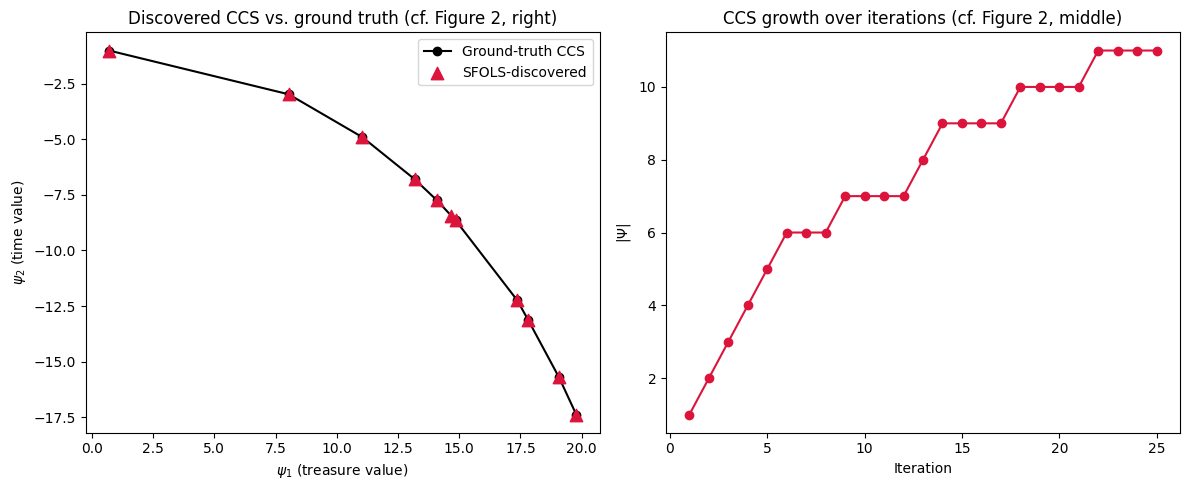

ground truth [ 0.7 -1. ] -> nearest discovered [ 0.7 -1. ] (dist=0.000)
ground truth [ 8.037 -2.97 ] -> nearest discovered [ 8.037 -2.97 ] (dist=0.000)
ground truth [11.047 -4.901] -> nearest discovered [11.047 -4.901] (dist=0.000)
ground truth [13.181 -6.793] -> nearest discovered [13.181 -6.793] (dist=0.000)
ground truth [14.074 -7.726] -> nearest discovered [14.074 -7.726] (dist=0.000)
ground truth [14.856 -8.648] -> nearest discovered [14.856 -8.648] (dist=0.000)
ground truth [ 17.373 -12.248] -> nearest discovered [ 17.373 -12.248] (dist=0.000)
ground truth [ 17.814 -13.125] -> nearest discovered [ 17.814 -13.125] (dist=0.000)
ground truth [ 19.073 -15.706] -> nearest discovered [ 19.073 -15.706] (dist=0.000)
ground truth [ 19.778 -17.383] -> nearest discovered [ 19.778 -17.383] (dist=0.000)


In [10]:
Psi_arr = np.array(Psi)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.plot(ground_truth_ccs[:, 0], ground_truth_ccs[:, 1], "o-", color="black", label="Ground-truth CCS", zorder=1)
ax.scatter(Psi_arr[:, 0], Psi_arr[:, 1], color="crimson", marker="^", s=80, label="SFOLS-discovered", zorder=2)
ax.set_xlabel(r"$\psi_1$ (treasure value)")
ax.set_ylabel(r"$\psi_2$ (time value)")
ax.set_title("Discovered CCS vs. ground truth (cf. Figure 2, right)")
ax.legend()

ax = axes[1]
iters, sizes, priorities = zip(*history)
ax.plot(iters, sizes, "o-", color="crimson")
ax.set_xlabel("Iteration")
ax.set_ylabel(r"$|\Psi|$")
ax.set_title("CCS growth over iterations (cf. Figure 2, middle)")

plt.tight_layout()
plt.show()

# how close is each ground-truth point to its nearest discovered policy?
for gt in ground_truth_ccs:
    dists = np.linalg.norm(Psi_arr - gt, axis=1)
    print(f"ground truth {gt.round(3)} -> nearest discovered {Psi_arr[dists.argmin()].round(3)} (dist={dists.min():.3f})")

## 6c. What do the discovered basis policies actually do?


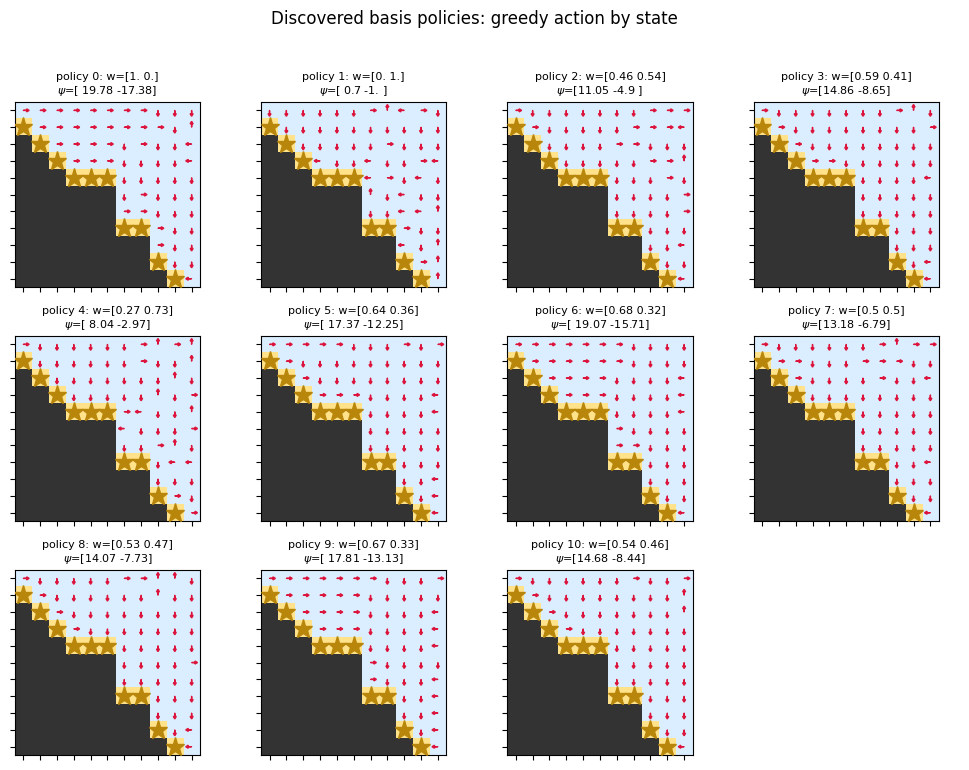

In [11]:
from matplotlib.colors import ListedColormap


def policy_weights(history, W_exp):
    """The weight w_i that produced Psi[i]/Pi[i]: W_exp[it - 1] at the iteration
    `it` where |Psi| grew from i to i + 1 (Psi/Pi are append-only and don't carry
    their weight, but history does, in lockstep with W_exp)."""
    weights, prev_size = [], 0
    for it, size, _ in history:
        if size > prev_size:
            weights.append(W_exp[it - 1])
            prev_size = size
    return weights


def plot_policy_arrows(ax, psi_table, w, sea_map, core, arrow_len=0.35):
    """Greedy action argmax_a psi(s, a) . w, drawn as an arrow at every sea cell."""
    nrows, ncols = sea_map.shape
    cell_type = np.where(sea_map == -10, 0, np.where(sea_map > 0, 2, 1))  # rock/sea/treasure
    cmap = ListedColormap(["#333333", "#dbeeff", "#ffe28a"])
    ax.imshow(cell_type, cmap=cmap, origin="upper", vmin=0, vmax=2)

    for r in range(nrows):
        for c in range(ncols):
            val = sea_map[r, c]
            if val == -10:
                continue  # rock: not a reachable state
            if val > 0:
                ax.plot(c, r, marker="*", color="darkgoldenrod", markersize=14, zorder=3)
                continue
            action = int(np.argmax(psi_table[(r, c)] @ w))
            drow, dcol = core.dir[action]
            ax.arrow(c, r, dcol * arrow_len, drow * arrow_len, head_width=0.18, head_length=0.15,
                      fc="crimson", ec="crimson", length_includes_head=True, zorder=3)

    ax.set_xticks(range(ncols))
    ax.set_yticks(range(nrows))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_aspect("equal")


W_used = policy_weights(history, W_exp)

n_cols = 4
n_rows = -(-len(Pi) // n_cols)  # ceil division
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.5 * n_cols, 2.5 * n_rows))
axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):
    if i < len(Pi):
        plot_policy_arrows(ax, Pi[i], W_used[i], core.sea_map, core)
        ax.set_title(f"policy {i}: w={W_used[i].round(2)}\n" + r"$\psi$=" + f"{Psi[i].round(2)}", fontsize=8)
    else:
        ax.axis("off")

fig.suptitle("Discovered basis policies: greedy action by state", y=1.02)
plt.tight_layout()
plt.show()

## 6a. Watching the SMP envelope grow, iteration by iteration


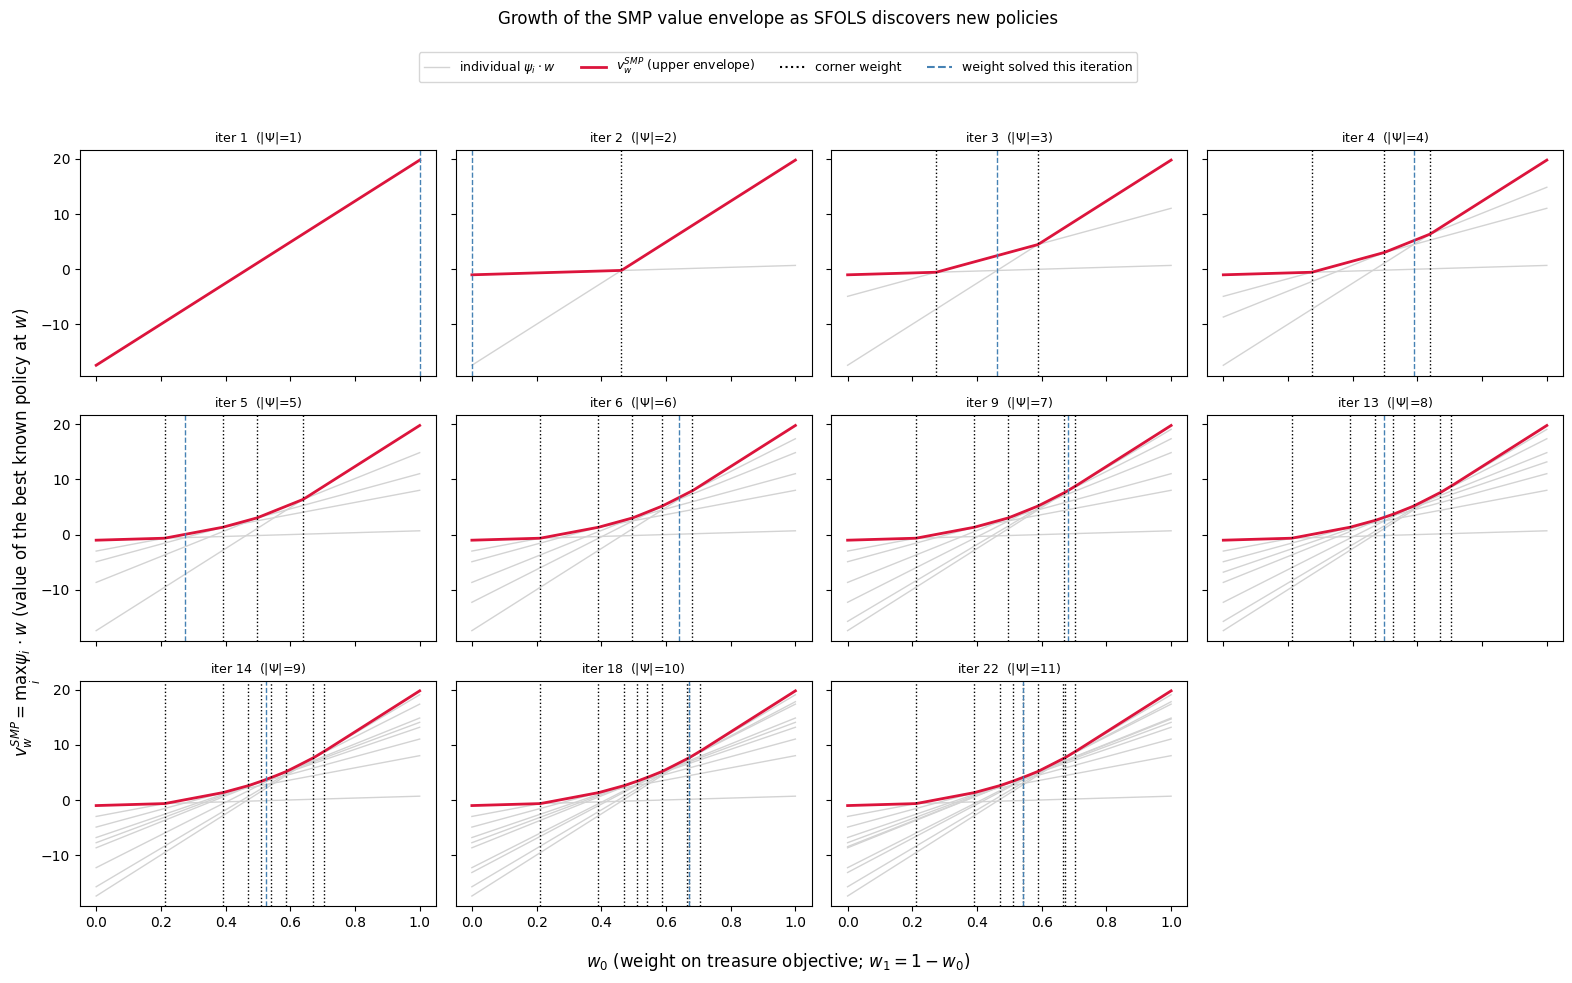

In [12]:
growth_snapshots = [(it, size) for idx, (it, size, _) in enumerate(history) if idx == 0 or size != history[idx - 1][1]]

n_cols = 4
n_rows = -(-len(growth_snapshots) // n_cols)  # ceil division
w0_grid = np.linspace(0.0, 1.0, 200)
weights = np.stack([w0_grid, 1 - w0_grid], axis=1)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows), sharex=True, sharey=True)
axes = np.array(axes).reshape(-1)

for ax, (it, size) in zip(axes, growth_snapshots):
    psi_so_far = Psi[:size]  # Psi is append-only, so this is exactly what it looked like after iteration `it`

    for psi_i in psi_so_far:
        ax.plot(w0_grid, weights @ psi_i, color="lightgray", lw=1)
    ax.plot(w0_grid, (weights @ np.array(psi_so_far).T).max(axis=1), color="crimson", lw=2)

    for wc in corner_weights_2d(psi_so_far):
        ax.axvline(wc[0], color="black", ls=":", lw=1)
    ax.axvline(W_exp[it - 1][0], color="steelblue", ls="--", lw=1)

    ax.set_title(f"iter {it}  ($|\\Psi|$={size})", fontsize=9)

for ax in axes[len(growth_snapshots):]:
    ax.axis("off")

handles = [
    plt.Line2D([0], [0], color="lightgray", lw=1, label=r"individual $\psi_i \cdot w$"),
    plt.Line2D([0], [0], color="crimson", lw=2, label=r"$v^{SMP}_w$ (upper envelope)"),
    plt.Line2D([0], [0], color="black", ls=":", label="corner weight"),
    plt.Line2D([0], [0], color="steelblue", ls="--", label="weight solved this iteration"),
]
fig.legend(handles=handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04), fontsize=9)
fig.supxlabel(r"$w_0$ (weight on treasure objective; $w_1 = 1 - w_0$)")
fig.supylabel(r"$v^{SMP}_w = \max_i \psi_i \cdot w$ (value of the best known policy at $w$)")
fig.suptitle("Growth of the SMP value envelope as SFOLS discovers new policies", y=1.08)
plt.tight_layout()
plt.show()

## 6b. Which policy's SF does GPI pick, by state and by weight?

In [2]:
from matplotlib.collections import LineCollection


def state_policy_values(state, Pi, w0_grid):
    """values[i, j] = max_a psi_i(state, a) . [w0_grid[j], 1 - w0_grid[j]] -- the same
    per-table maximization gpi_action does, just kept separate per table instead of
    immediately collapsing to the argmax over i."""
    weights = np.stack([w0_grid, 1 - w0_grid], axis=1)  # (n_grid, 2)
    return np.stack([(weights @ psi_table[state].T).max(axis=1) for psi_table in Pi])


def plot_policy_switches_by_state(states, Pi, Psi, n_grid=1000):
    """One horizontal line per state; its color at each w0 is whichever policy's SF
    is currently GPI-greedy there. Black ticks mark the corner weights -- the points
    where the winning successor feature changes -- computed locally at that state."""
    w0_grid = np.linspace(0.0, 1.0, n_grid)
    cmap = plt.get_cmap("tab20")
    colors = [cmap(i % 20) for i in range(len(Pi))]

    fig, ax = plt.subplots(figsize=(10, 0.7 * len(states) + 1.5))
    for row, state in enumerate(states):
        winner = state_policy_values(state, Pi, w0_grid).argmax(axis=0)
        segments = [[(w0_grid[j], row), (w0_grid[j + 1], row)] for j in range(n_grid - 1)]
        ax.add_collection(LineCollection(segments, colors=[colors[w] for w in winner[:-1]], linewidth=14))
        for s in np.flatnonzero(np.diff(winner) != 0):
            ax.plot(w0_grid[s], row, "|", color="black", markersize=18, mew=1.5, zorder=3)

    ax.set_xlim(0, 1)
    ax.set_ylim(-0.5, len(states) - 0.5)
    ax.set_yticks(range(len(states)))
    ax.set_yticklabels([str(s) for s in states])
    ax.invert_yaxis()
    ax.set_xlabel(r"$w_0$ (weight on treasure objective; $w_1 = 1 - w_0$)")
    ax.set_title("Which discovered policy's SF is GPI-greedy, by state and weight")

    handles = [
        plt.Line2D([0], [0], color=colors[i], lw=8, label=rf"$\psi_{{{i}}}$ = {Psi[i].round(2)}")
        for i in range(len(Pi))
    ]
    ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="policy")
    plt.tight_layout()
    plt.show()

states_to_plot = [START_STATE, (0, 1), (1, 2), (2, 3), (3, 3)]
plot_policy_switches_by_state(states_to_plot, Pi, Psi)

NameError: name 'START_STATE' is not defined

## 7. Optimal policy transfer: solving a brand-new task with zero extra training

This is the paper's central payoff (Theorem 3.2): once `Psi` spans the CCS, GPI over the corresponding policies `Pi` is *optimal* for **any** new weight `w`, not just the ones SFOLS happened to solve directly. We test this on weights SFOLS never explicitly trained on and check the GPI policy's return against the ground-truth optimum.

In [14]:
def rollout_gpi(env, w, sf_tables, seed=None, max_steps=100):
    rng = random.Random((seed or 0) + 999)
    obs, _ = env.reset(seed=seed)
    path = [tuple(int(x) for x in obs)]
    phis = []
    for _ in range(max_steps):
        action = gpi_action(rng, path[-1], w, sf_tables)
        obs, phi, terminated, truncated, _ = env.step(action)
        path.append(tuple(int(x) for x in obs))
        phis.append(phi)
        if terminated or truncated:
            break
    return path, phis


solved_w0s = {round(float(w[0]), 3) for w in W_exp}
test_w0s = [w0 for w0 in [0.15, 0.35, 0.55, 0.63, 0.85] if round(w0, 3) not in solved_w0s]

for w0 in test_w0s:
    w = np.array([w0, 1 - w0])
    predicted = ground_truth_ccs[np.argmax(ground_truth_ccs @ w)]
    path, phis = rollout_gpi(env, w, Pi, seed=42)
    total_undiscounted = np.sum(phis, axis=0)
    print(f"w0={w0:.2f} (never solved directly): GPI reaches treasure {total_undiscounted[0]:.1f} "
          f"in {len(path)-1} steps -- ground truth optimal treasure: {round(predicted[0]):.0f}")

w0=0.15 (never solved directly): GPI reaches treasure 0.7 in 1 steps -- ground truth optimal treasure: 1
w0=0.35 (never solved directly): GPI reaches treasure 8.2 in 3 steps -- ground truth optimal treasure: 8
w0=0.55 (never solved directly): GPI reaches treasure 0.0 in 100 steps -- ground truth optimal treasure: 15
w0=0.63 (never solved directly): GPI reaches treasure 0.0 in 100 steps -- ground truth optimal treasure: 17
w0=0.85 (never solved directly): GPI reaches treasure 0.0 in 100 steps -- ground truth optimal treasure: 20


## 8. TrainOK: composing an unseen weight from just two corner policies

Fix Π = {π_[1,0], π_[0,1]} — the two simplex extremes, deepest and shallowest treasure — and train a meta-policy ω(s) so that π^OK = GPI(z=ω(s), Π) reproduces the optimal policy for w = [0.2, 0.8], a weight neither corner policy was trained on.

In [15]:
def step_deterministic(s, a):
    ns = (s[0] + int(core.dir[a][0]), s[1] + int(core.dir[a][1]))
    if not (0 <= ns[0] <= 10 and 0 <= ns[1] <= 10) or core.sea_map[ns] == -10:
        ns = s
    treasure = core.sea_map[ns]
    terminal = treasure != 0 and treasure != -10
    phi = np.array([treasure if terminal else 0.0, -1.0])
    return ns, phi, terminal


nrows, ncols = core.sea_map.shape
states = [(r, c) for r in range(nrows) for c in range(ncols) if core.sea_map[r, c] != -10]
is_terminal = {s: core.sea_map[s] != 0 for s in states}
state_idx = {s: i for i, s in enumerate(states)}
n_states = len(states)


def policy_iteration(w, gamma=GAMMA):
    policy = {s: 0 for s in states if not is_terminal[s]}
    while True:
        A, b = np.eye(n_states), np.zeros(n_states)
        for s in states:
            if is_terminal[s]:
                continue
            i = state_idx[s]
            ns, phi, term = step_deterministic(s, policy[s])
            b[i] = phi @ w
            if not term:
                A[i, state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[state_idx[s]] for s in states}

        stable = True
        for s in states:
            if is_terminal[s]:
                continue
            qs = []
            for a in range(N_ACTIONS):
                ns, phi, term = step_deterministic(s, a)
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V


def solve_task_exact(w, gamma=GAMMA):
    policy, _ = policy_iteration(w, gamma)
    A, b = np.eye(n_states), np.zeros((n_states, FEAT_DIM))
    for s in states:
        if is_terminal[s]:
            continue
        i = state_idx[s]
        ns, phi, term = step_deterministic(s, policy[s])
        b[i] = phi
        if not term:
            A[i, state_idx[ns]] -= gamma
    V = np.linalg.solve(A, b)
    V = {s: V[state_idx[s]] for s in states}

    psi = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in states:
        if is_terminal[s]:
            continue
        table = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(s, a)
            table[a] = phi if term else phi + gamma * V[ns]
        psi.table[s] = table
    return psi

In [16]:
w_target = np.array([0.2, 0.8])
psi_deep = solve_task_exact(np.array([1.0, 0.0]))
psi_shallow = solve_task_exact(np.array([0.0, 1.0]))
Pi_base = [psi_deep, psi_shallow]
W_base = [np.array([1.0, 0.0]), np.array([0.0, 1.0])]  # each Pi_base[j]'s own training weight

optimal = ground_truth_ccs[np.argmax(ground_truth_ccs @ w_target)]
policy_opt, V_opt = policy_iteration(w_target)
print(f"target weight w={w_target}, ground-truth optimal psi={optimal}, value={optimal @ w_target:.3f}")
print(f"optimal value at {START_STATE}: policy iteration={V_opt[START_STATE]:.3f}  ground-truth CCS={float(optimal @ w_target):.3f}")

target weight w=[0.2 0.8], ground-truth optimal psi=[ 0.7 -1. ], value=-0.660
optimal value at (0, 0): policy iteration=-0.660  ground-truth CCS=-0.660


In [17]:
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F

nrows, ncols = core.sea_map.shape

def normalize(state):
    return np.array([state[0] / (nrows - 1), state[1] / (ncols - 1)], dtype=np.float32)


class MetaPolicy(nn.Module):
    def __init__(self, state_dim, feat_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, feat_dim))

    def logits(self, s):
        return self.net(s)

    def forward(self, s):
        return F.softmax(self.logits(s), dim=-1)


class MetaCritic(nn.Module):
    def __init__(self, state_dim, feat_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_dim + feat_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, feat_dim))

    def forward(self, s, z):
        return self.net(torch.cat([s, z], dim=-1))


class ReplayBuffer:
    """Proportional prioritized replay: transitions are sampled with probability
    proportional to priority**alpha, where priority is the last-seen TD-error norm.
    This upweights transitions the critic is still getting wrong -- e.g. the small
    minority of states near the deep-treasure switching boundary -- instead of
    letting their gradient be drowned out every batch by the much larger majority
    of states where the critic has already converged. New transitions are inserted
    at max_priority so they get sampled (and thus actually evaluated) at least once.

    Sampling uses a cached cumulative distribution (refreshed every `refresh_every`
    calls, not every call) plus np.searchsorted -- np.random.Generator.choice(p=...)
    rebuilds an equivalent O(size) cumulative sum internally on *every* call, which
    measured ~30x slower than uniform sampling at this buffer's size and made
    500k-step training impractically slow. Priorities go a few steps stale between
    refreshes; harmless for what this is used for.
    """

    def __init__(self, capacity, state_dim, feat_dim, alpha=0.6, beta=0.4, eps=1e-3, refresh_every=8):
        self.s = np.zeros((capacity, state_dim), dtype=np.float32)
        self.z = np.zeros((capacity, feat_dim), dtype=np.float32)
        self.phi = np.zeros((capacity, feat_dim), dtype=np.float32)
        self.s_next = np.zeros((capacity, state_dim), dtype=np.float32)
        self.done = np.zeros((capacity,), dtype=np.float32)
        self.priority = np.zeros((capacity,), dtype=np.float32)
        self.capacity, self.ptr, self.size = capacity, 0, 0
        self.alpha, self.beta, self.eps = alpha, beta, eps
        self.max_priority = 1.0
        self.refresh_every = refresh_every
        self._calls = 0
        self._probs = None
        self._cumsum = None

    def add(self, s, z, phi, s_next, done):
        i = self.ptr
        self.s[i], self.z[i], self.phi[i] = s, z, phi
        self.s_next[i], self.done[i] = s_next, float(done)
        self.priority[i] = self.max_priority
        self.ptr = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, rng):
        if self._probs is None or self._calls % self.refresh_every == 0:
            raw = self.priority[:self.size] ** self.alpha
            self._probs = raw / raw.sum()
            self._cumsum = np.cumsum(self._probs)
        self._calls += 1

        draws = rng.random(batch_size) * self._cumsum[-1]
        idx = np.clip(np.searchsorted(self._cumsum, draws), 0, self.size - 1)
        weights = (self.size * self._probs[idx]) ** (-self.beta)
        weights /= weights.max()
        return (self.s[idx], self.z[idx], self.phi[idx], self.s_next[idx], self.done[idx],
                idx, weights.astype(np.float32))

    def update_priorities(self, idx, td_error_norm):
        priority = np.abs(td_error_norm) + self.eps
        self.priority[idx] = priority
        self.max_priority = max(self.max_priority, float(priority.max()))

In [18]:
def select_policy_action(rng, state, z, Pi_base, W_base):
    """j(z) = argmax_j psi_j(s, pi_j(s)) . z, then take a = pi_j(s).

    Unlike `gpi_action` -- which jointly maximizes over (policy, action) and so can
    stitch together an action no base policy would ever take on its own -- this
    first fixes each base policy's own greedy action pi_j(s) = argmax_a psi_j(s, a) . w_j
    (under its own training weight w_j), then argmaxes over j only. z picks *which*
    policy to run at s; it never re-optimizes the action within a state.

    pi_j(s) uses a fixed (lowest-index) tie-break: which of several equally-optimal
    actions a base policy takes is irrelevant to its own value, but it's *not*
    irrelevant to omega -- if it varied randomly, identical (s, z) pairs would
    route to different successor states purely by tie luck, adding noise the actor
    has no way to learn from. Only the choice of *which* policy to run (j, driven
    by the learnable z) keeps gpi_action's random tie-breaking, since that choice
    is genuinely allowed to be ambiguous/exploratory.
    """
    own_actions = []
    own_values = np.empty(len(Pi_base))
    for j, (sft, w_j) in enumerate(zip(Pi_base, W_base)):
        q = sft[state] @ w_j
        a_j = int(np.argmax(q))
        own_actions.append(a_j)
        own_values[j] = sft[state][a_j] @ z

    candidates = np.flatnonzero(np.isclose(own_values, own_values.max()))
    j = int(rng.choice(candidates))
    return own_actions[j]

In [19]:
def train_ok_single(env, eval_env, w, Pi_base, W_base, num_steps=500_000, batch_size=128,
                     gamma=GAMMA, actor_lr=1e-4, critic_lr=1e-4, buffer_capacity=10_000,
                     noise_std_start=2.0, noise_std_end=0.1, noise_decay_frac=1.0,
                     tau=0.005, policy_delay=2, target_noise_std=0.5, seed=0,
                     min_iter=10_000, critic_warmup_steps=5_000, eval_interval=500,
                     per_alpha=0.6, per_beta=0.4, entropy_coef=0.1):
    rng = np.random.default_rng(seed)
    py_rng = random.Random(seed)
    w_t = torch.as_tensor(w, dtype=torch.float32)
    feat_dim = len(w)

    nonterminal_states = [s for s in states if not is_terminal[s]]

    def random_reset(seed=None):
        """Reset a training episode to a uniformly random non-terminal state instead
        of always (0,0). DeepSeaTreasure.reset() hardcodes current_state=(0,0), so we
        call it first (to reset step_count etc.) then overwrite current_state directly
        -- otherwise every training episode only ever visits states reachable from
        (0,0) via {deep, shallow} action switching, which is a small minority of the
        state space (many cells are unreachable that way no matter how long we train)."""
        env.reset(seed=seed)
        s0 = nonterminal_states[py_rng.randrange(len(nonterminal_states))]
        env.unwrapped.current_state = np.array(s0, dtype=np.int32)
        return s0

    omega = MetaPolicy(2, feat_dim)
    psi_omega = MetaCritic(2, feat_dim)
    omega_t, psi_t = copy.deepcopy(omega), copy.deepcopy(psi_omega)
    for p in omega_t.parameters(): p.requires_grad_(False)
    for p in psi_t.parameters(): p.requires_grad_(False)

    actor_opt = torch.optim.Adam(omega.parameters(), lr=actor_lr)
    critic_opt = torch.optim.Adam(psi_omega.parameters(), lr=critic_lr)
    buffer = ReplayBuffer(buffer_capacity, 2, feat_dim, alpha=per_alpha, beta=per_beta)

    history = {"critic_steps": [], "critic_loss": [], "actor_steps": [], "actor_loss": [],
               "actor_entropy": [], "eval_steps": [], "eval_vals": []}

    def eval_omega():
        obs, _ = eval_env.reset(seed=seed)
        state = tuple(int(x) for x in obs)
        disc, ret = 1.0, 0.0
        for _ in range(100):
            with torch.no_grad():
                z = omega(torch.as_tensor(normalize(state)).unsqueeze(0)).squeeze(0).numpy()
            action = select_policy_action(py_rng, state, z, Pi_base, W_base)
            obs, phi, term, trunc, _ = eval_env.step(action)
            state = tuple(int(x) for x in obs)
            ret += disc * float(np.dot(phi, w))
            disc *= gamma
            if term or trunc:
                break
        return ret

    actor_steps = num_steps - critic_warmup_steps
    state = random_reset(seed=seed)
    best_val, best_omega = -np.inf, copy.deepcopy(omega.state_dict())

    for t in range(num_steps):
        if t < critic_warmup_steps:
            noise_std = noise_std_start
        else:
            t_since = t - critic_warmup_steps
            noise_std = max(noise_std_end, noise_std_start - (noise_std_start - noise_std_end) * t_since / (noise_decay_frac * actor_steps))

        obs_n = normalize(state)
        with torch.no_grad():
            logits = omega.logits(torch.as_tensor(obs_n).unsqueeze(0)).squeeze(0).numpy()
        logits = logits + rng.normal(0, noise_std, feat_dim)
        z = F.softmax(torch.as_tensor(logits, dtype=torch.float32), dim=-1).numpy()

        action = select_policy_action(py_rng, state, z, Pi_base, W_base)
        next_obs, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(int(x) for x in next_obs)
        buffer.add(obs_n, z, phi, normalize(next_state), terminated)

        if terminated or truncated:
            state = random_reset()
        else:
            state = next_state

        if buffer.size >= batch_size:
            s_b, z_b, phi_b, s_next_b, done_b, idx_b, is_w = buffer.sample(batch_size, rng)
            s_b, z_b, phi_b, s_next_b = (torch.as_tensor(x) for x in (s_b, z_b, phi_b, s_next_b))
            done_b = torch.as_tensor(done_b).unsqueeze(-1)
            is_w_t = torch.as_tensor(is_w).unsqueeze(-1)

            with torch.no_grad():
                logits_next = omega_t.logits(s_next_b)
                logits_next = logits_next + torch.clamp(torch.randn_like(logits_next) * target_noise_std, -1.0, 1.0)
                z_next = F.softmax(logits_next, dim=-1)
                target = phi_b + gamma * (1 - done_b) * psi_t(s_next_b, z_next)

            td_error = psi_omega(s_b, z_b) - target
            critic_loss = (is_w_t * td_error.pow(2)).mean()
            critic_opt.zero_grad(); critic_loss.backward(); critic_opt.step()
            buffer.update_priorities(idx_b, td_error.detach().norm(dim=-1).numpy())
            history["critic_steps"].append(t)
            history["critic_loss"].append(float(critic_loss.item()))

            if t >= min_iter and t % eval_interval == 0:
                val = eval_omega()
                history["eval_steps"].append(t)
                history["eval_vals"].append(val)
                if val > best_val:
                    best_val, best_omega = val, copy.deepcopy(omega.state_dict())

            if t % policy_delay == 0:
                with torch.no_grad():
                    for p, tp in zip(psi_omega.parameters(), psi_t.parameters()):
                        tp.data.mul_(1 - tau).add_(tau * p.data)

                if t >= critic_warmup_steps:
                    z_pi = omega(s_b)
                    q_pi = (psi_omega(s_b, z_pi) * w_t).sum(-1)
                    entropy = -(z_pi * torch.log(z_pi.clamp_min(1e-8))).sum(-1)
                    actor_loss = -(q_pi + entropy_coef * entropy).mean()
                    actor_opt.zero_grad(); actor_loss.backward(); actor_opt.step()
                    history["actor_steps"].append(t)
                    history["actor_loss"].append(float(actor_loss.item()))
                    history["actor_entropy"].append(float(entropy.mean().item()))
                    with torch.no_grad():
                        for p, tp in zip(omega.parameters(), omega_t.parameters()):
                            tp.data.mul_(1 - tau).add_(tau * p.data)

    omega.load_state_dict(best_omega)
    return omega, psi_omega, best_val, history


eval_env = mo_gym.make("deep-sea-treasure-v0")
omega, psi_omega, best_val, train_history = train_ok_single(env, eval_env, w_target, Pi_base, W_base, seed=0)
print(f"best eval return during training: {best_val:.3f}")

/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gymnasium/spaces/box.py:297: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


best eval return during training: -0.660


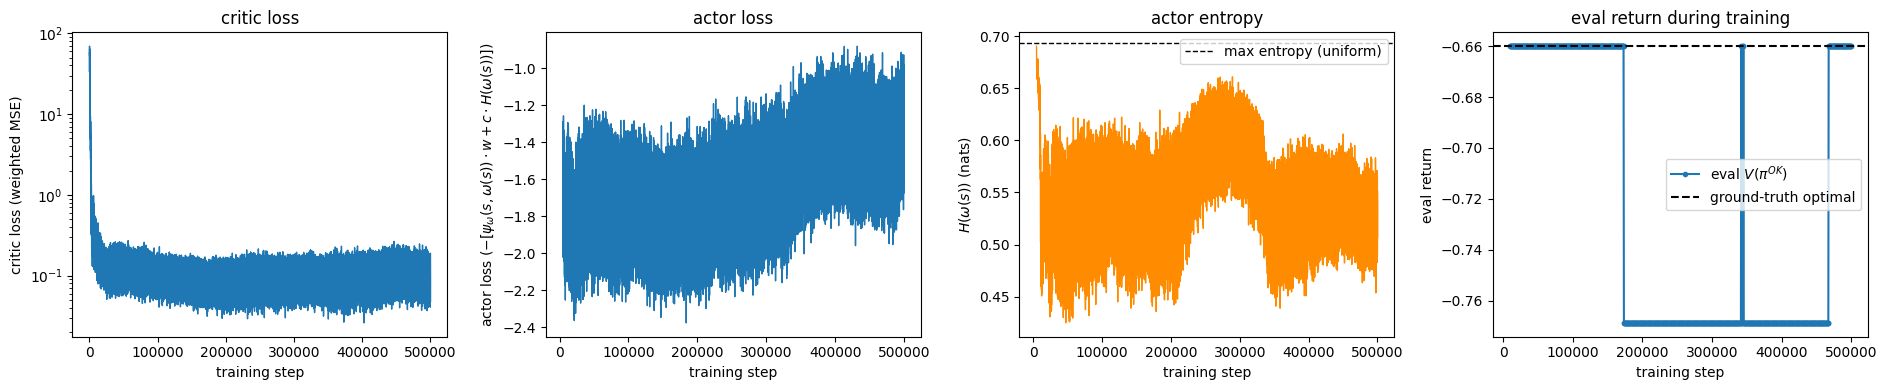

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4))

axes[0].plot(train_history["critic_steps"], train_history["critic_loss"], lw=1)
axes[0].set_yscale("log")
axes[0].set_xlabel("training step")
axes[0].set_ylabel("critic loss (weighted MSE)")
axes[0].set_title("critic loss")

axes[1].plot(train_history["actor_steps"], train_history["actor_loss"], lw=1)
axes[1].set_xlabel("training step")
axes[1].set_ylabel(r"actor loss ($-[\psi_\omega(s,\omega(s))\cdot w + c \cdot H(\omega(s))]$)")
axes[1].set_title("actor loss")

axes[2].plot(train_history["actor_steps"], train_history["actor_entropy"], lw=1, color="darkorange")
axes[2].axhline(np.log(2), color="black", ls="--", lw=1, label="max entropy (uniform)")
axes[2].set_xlabel("training step")
axes[2].set_ylabel(r"$H(\omega(s))$ (nats)")
axes[2].set_title("actor entropy")
axes[2].legend()

axes[3].plot(train_history["eval_steps"], train_history["eval_vals"], marker="o", ms=3, label=r"eval $V(\pi^{OK})$")
axes[3].axhline(float(optimal @ w_target), color="black", ls="--", label="ground-truth optimal")
axes[3].set_xlabel("training step")
axes[3].set_ylabel("eval return")
axes[3].set_title("eval return during training")
axes[3].legend()

plt.tight_layout()
plt.show()

In [21]:
rng_eval = random.Random(1)

def rollout(action_fn, seed=1, max_steps=100):
    obs, _ = env.reset(seed=seed)
    state = tuple(int(x) for x in obs)
    disc, ret = 1.0, 0.0
    for _ in range(max_steps):
        action = action_fn(state)
        obs, phi, terminated, truncated, _ = env.step(action)
        state = tuple(int(x) for x in obs)
        ret += disc * float(np.dot(phi, w_target))
        disc *= GAMMA
        if terminated or truncated:
            break
    return ret


def ok_action(state):
    with torch.no_grad():
        z = omega(torch.as_tensor(normalize(state)).unsqueeze(0)).squeeze(0).numpy()
    return select_policy_action(rng_eval, state, z, Pi_base, W_base)


optimal_return = float(optimal @ w_target)
gpi_return = rollout(lambda s: gpi_action(rng_eval, s, w_target, Pi_base))
ok_return = rollout(ok_action)

print(f"optimal (ground truth)     = {optimal_return:.3f}")
print(f"GPI over 2 corners (fixed) = {gpi_return:.3f}")
print(f"pi^OK (trained omega)      = {ok_return:.3f}")

optimal (ground truth)     = -0.660
GPI over 2 corners (fixed) = -0.660
pi^OK (trained omega)      = -0.660


In [22]:
def evaluate_policy(action_fn, w=w_target, gamma=GAMMA):
    """Exact value function of a fixed deterministic policy, via a single Bellman
    solve -- the env is deterministic, so (unlike policy_iteration) one linear
    solve is exact; no need to iterate policy improvement to convergence."""
    policy = {s: action_fn(s) for s in states if not is_terminal[s]}
    A, b = np.eye(n_states), np.zeros(n_states)
    for s in states:
        if is_terminal[s]:
            continue
        i = state_idx[s]
        ns, phi, term = step_deterministic(s, policy[s])
        b[i] = phi @ w
        if not term:
            A[i, state_idx[ns]] -= gamma
    v = np.linalg.solve(A, b)
    return {s: v[state_idx[s]] for s in states}


V_gpi = evaluate_policy(lambda s: gpi_action(rng_eval, s, w_target, Pi_base))
V_ok = evaluate_policy(ok_action)

nonterminal = [s for s in states if not is_terminal[s]]
sum_opt = sum(V_opt[s] for s in nonterminal)
sum_gpi = sum(V_gpi[s] for s in nonterminal)
sum_ok = sum(V_ok[s] for s in nonterminal)
n_mismatch_gpi = sum(not np.isclose(V_opt[s], V_gpi[s], atol=1e-6) for s in nonterminal)
n_mismatch_ok = sum(not np.isclose(V_opt[s], V_ok[s], atol=1e-6) for s in nonterminal)

print(f"sum of V(s) over {len(nonterminal)} non-terminal states, w={w_target}")
print(f"  optimal (policy iteration) = {sum_opt:.3f}")
print(f"  GPI over 2 corners (fixed) = {sum_gpi:.3f}  ({n_mismatch_gpi}/{len(nonterminal)} states suboptimal)")
print(f"  pi^OK (trained omega)      = {sum_ok:.3f}  ({n_mismatch_ok}/{len(nonterminal)} states suboptimal)")

sum of V(s) over 62 non-terminal states, w=[0.2 0.8]
  optimal (policy iteration) = 39.589
  GPI over 2 corners (fixed) = 39.511  (11/62 states suboptimal)
  pi^OK (trained omega)      = 36.434  (22/62 states suboptimal)


## 8e. Exact policy iteration over the composition -- no actor-critic needed

In [ ]:
def own_greedy_actions(sf_table, w):
    """pi_j(s) = argmax_a psi_j(s, a) . w_j, precomputed once per base policy -- the
    same per-table greedy action select_policy_action recomputes on every call."""
    return {s: int(np.argmax(sf_table[s] @ w)) for s in states if not is_terminal[s]}


def meta_policy_iteration(w, Pi_base, W_base, gamma=GAMMA):
    """Exact policy iteration over the meta-MDP whose actions are *which base policy's
    own action to take*, not which direction to move. Own actions and the environment
    are both deterministic, so both evaluation and improvement are exact -- no sampling,
    no function approximation, no training instability."""
    own_actions = [own_greedy_actions(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    meta_policy = {s: 0 for s in states if not is_terminal[s]}

    while True:
        A, b = np.eye(n_states), np.zeros(n_states)
        for s in states:
            if is_terminal[s]:
                continue
            i = state_idx[s]
            ns, phi, term = step_deterministic(s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[state_idx[s]] for s in states}

        stable = True
        for s in states:
            if is_terminal[s]:
                continue
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = step_deterministic(s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable:
            return meta_policy, V, own_actions



meta_policy, V_meta, own_actions = meta_policy_iteration(w_target, Pi_base, W_base)

def meta_action(state):
    return own_actions[meta_policy[state]][state]

sum_meta = sum(V_meta[s] for s in nonterminal)
n_mismatch_meta = sum(not np.isclose(V_opt[s], V_meta[s], atol=1e-6) for s in nonterminal)
n_diff_ok_meta = sum(meta_action(s) != ok_action(s) for s in nonterminal)

print(f"sum of V(s) over {len(nonterminal)} non-terminal states, w={w_target}")
print(f"  optimal (policy iteration)  = {sum_opt:.3f}")
print(f"  GPI over 2 corners (fixed)  = {sum_gpi:.3f}  ({n_mismatch_gpi}/{len(nonterminal)} states suboptimal)")
print(f"  pi^OK (trained omega)       = {sum_ok:.3f}  ({n_mismatch_ok}/{len(nonterminal)} states suboptimal)")
print(f"  exact meta policy iteration = {sum_meta:.3f}  ({n_mismatch_meta}/{len(nonterminal)} states suboptimal)")
print(f"  meta vs pi^OK action disagreement: {n_diff_ok_meta}/{len(nonterminal)} states")

sum of V(s) over 62 non-terminal states, w=[0.2 0.8]
  optimal (policy iteration)  = 39.589
  GPI over 2 corners (fixed)  = 39.546  (6/62 states suboptimal)
  pi^OK (trained omega)       = 33.834  (25/62 states suboptimal)
  exact meta policy iteration = 39.589  (0/62 states suboptimal)
  meta vs pi^OK action disagreement: 4/62 states


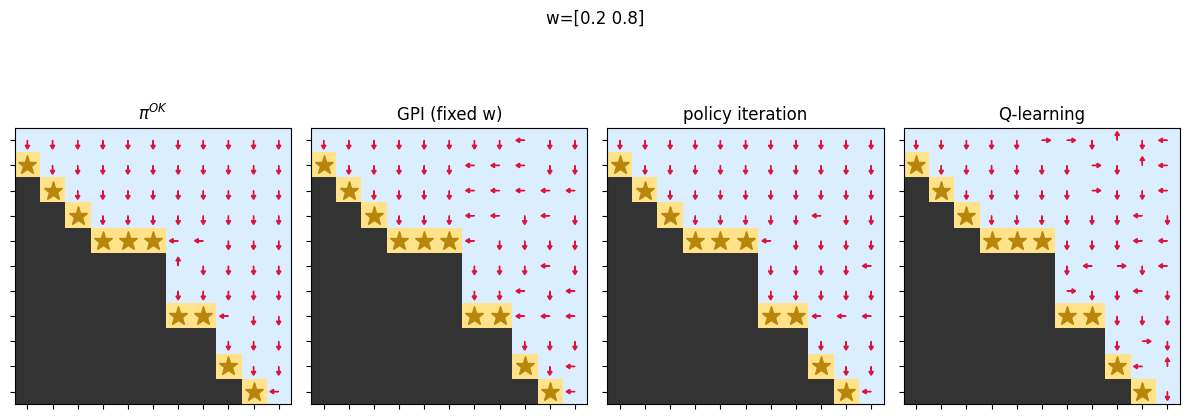

In [24]:
def plot_arrows(ax, action_fn, sea_map, core, arrow_len=0.35):
    nrows, ncols = sea_map.shape
    cell_type = np.where(sea_map == -10, 0, np.where(sea_map > 0, 2, 1))
    cmap = ListedColormap(["#333333", "#dbeeff", "#ffe28a"])
    ax.imshow(cell_type, cmap=cmap, origin="upper", vmin=0, vmax=2)

    for r in range(nrows):
        for c in range(ncols):
            val = sea_map[r, c]
            if val == -10:
                continue
            if val > 0:
                ax.plot(c, r, marker="*", color="darkgoldenrod", markersize=14, zorder=3)
                continue
            action = action_fn((r, c))
            drow, dcol = core.dir[action]
            ax.arrow(c, r, dcol * arrow_len, drow * arrow_len, head_width=0.18, head_length=0.15,
                      fc="crimson", ec="crimson", length_includes_head=True, zorder=3)

    ax.set_xticks(range(ncols))
    ax.set_yticks(range(nrows))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_aspect("equal")


psi_direct = solve_task(env, w_target, seed=200)

fig, axes = plt.subplots(1, 4, figsize=(12, 5))
plot_arrows(axes[0], ok_action, core.sea_map, core)
axes[0].set_title(r"$\pi^{OK}$")
plot_arrows(axes[1], lambda s: gpi_action(rng_eval, s, w_target, Pi_base), core.sea_map, core)
axes[1].set_title("GPI (fixed w)")
plot_arrows(axes[2], lambda s: policy_opt[s], core.sea_map, core)
axes[2].set_title("policy iteration")
plot_arrows(axes[3], lambda s: int(np.argmax(psi_direct[s] @ w_target)), core.sea_map, core)
axes[3].set_title("Q-learning")
fig.suptitle(f"w={w_target}")
plt.tight_layout()
plt.show()

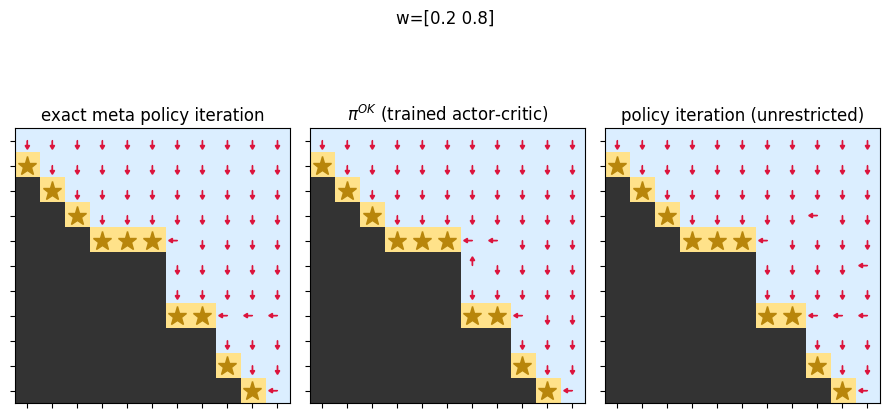

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(9, 5))
plot_arrows(axes[0], meta_action, core.sea_map, core)
axes[0].set_title("exact meta policy iteration")
plot_arrows(axes[1], ok_action, core.sea_map, core)
axes[1].set_title(r"$\pi^{OK}$ (trained actor-critic)")
plot_arrows(axes[2], lambda s: policy_opt[s], core.sea_map, core)
axes[2].set_title("policy iteration (unrestricted)")
fig.suptitle(f"w={w_target}")
plt.tight_layout()
plt.show()

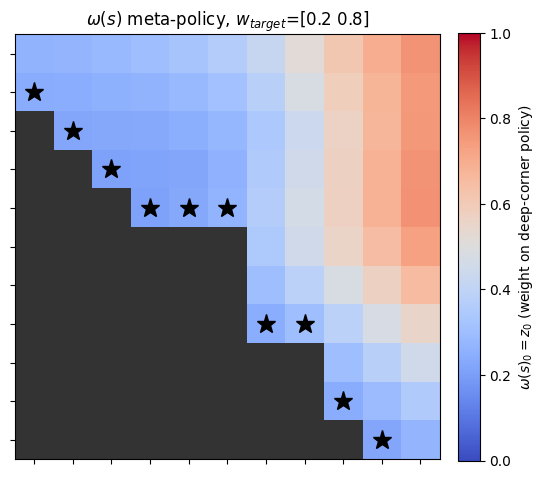

In [26]:
def plot_omega_heatmap(ax, sea_map, core):
    nrows, ncols = sea_map.shape
    z0 = np.full((nrows, ncols), np.nan)
    for r in range(nrows):
        for c in range(ncols):
            if sea_map[r, c] == -10:
                continue
            with torch.no_grad():
                z = omega(torch.as_tensor(normalize((r, c))).unsqueeze(0)).squeeze(0).numpy()
            z0[r, c] = z[0]

    cmap = plt.get_cmap("coolwarm").copy()
    cmap.set_bad("#333333")
    im = ax.imshow(z0, cmap=cmap, origin="upper", vmin=0, vmax=1)

    for r in range(nrows):
        for c in range(ncols):
            if sea_map[r, c] > 0:
                ax.plot(c, r, marker="*", color="black", markersize=14, zorder=3)

    ax.set_xticks(range(ncols))
    ax.set_yticks(range(nrows))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_aspect("equal")
    return im


fig, ax = plt.subplots(figsize=(5.5, 5))
im = plot_omega_heatmap(ax, core.sea_map, core)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label(r"$\omega(s)_0 = z_0$ (weight on deep-corner policy)")
ax.set_title(r"$\omega(s)$ meta-policy, $w_{target}$=" + f"{w_target}")
plt.tight_layout()
plt.show()

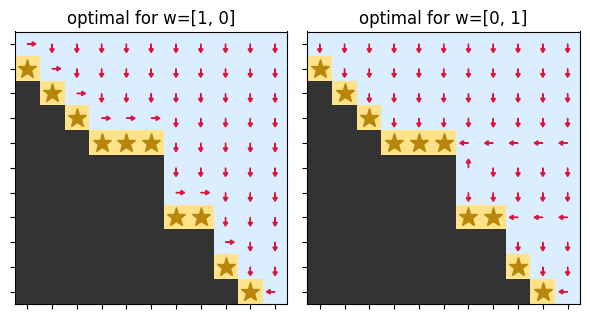

In [27]:
policy_deep, V_deep = policy_iteration(np.array([1.0, 0.0]))
policy_shallow, V_shallow = policy_iteration(np.array([0.0, 1.0]))

fig, axes = plt.subplots(1, 2, figsize=(6, 5))
plot_arrows(axes[0], lambda s: policy_deep[s], core.sea_map, core)
axes[0].set_title("optimal for w=[1, 0]")
plot_arrows(axes[1], lambda s: policy_shallow[s], core.sea_map, core)
axes[1].set_title("optimal for w=[0, 1]")
plt.tight_layout()
plt.show()

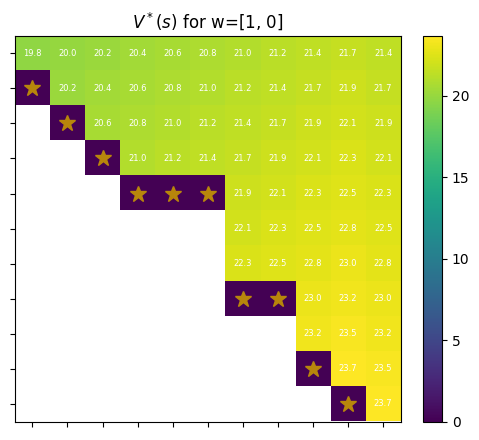

In [28]:
V_grid = np.full((nrows, ncols), np.nan)
for s in states:
    V_grid[s] = V_deep[s]

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(V_grid, cmap="viridis")
for s in states:
    if is_terminal[s]:
        ax.plot(s[1], s[0], marker="*", color="darkgoldenrod", markersize=12, zorder=3)
    else:
        ax.text(s[1], s[0], f"{V_deep[s]:.1f}", ha="center", va="center", fontsize=6, color="white")
ax.set_xticks(range(ncols))
ax.set_yticks(range(nrows))
ax.set_xticklabels([])
ax.set_yticklabels([])
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title(r"$V^*(s)$ for w=[1, 0]")
plt.tight_layout()
plt.show()

## 9. How few base policies does the meta-policy actually need?


In [ ]:
def meta_corner_weights_2d(Pi_base, W_base, gamma=GAMMA, n_grid=2000):
    """Corner weights of V^meta's OWN envelope: where meta_policy_iteration's chosen
    per-state assignment (which base policy each state defers to) changes as w0 sweeps
    [0, 1]. Deliberately NOT corner_weights_2d(Psi) -- composition can create breakpoints
    finer than any individual base policy's raw argmax switches (see the markdown note
    above), so those are the ones that matter for the convexity argument to apply."""
    w0_grid = np.linspace(0.0, 1.0, n_grid)
    corners = []
    prev_assignment = None
    for w0 in w0_grid:
        w = np.array([w0, 1 - w0])
        meta_policy, _, _ = meta_policy_iteration(w, Pi_base, W_base, gamma)
        assignment = tuple(meta_policy[s] for s in nonterminal)
        if prev_assignment is not None and assignment != prev_assignment:
            corners.append(w0)
        prev_assignment = assignment
    return [np.array([w0, 1 - w0]) for w0 in corners]


def minimal_meta_basis(num_objectives=2, gamma=GAMMA, tol=1e-6, n_grid=1000,
                        max_iterations=15, verbose=True):
    """SFOLS-style main loop, but the accept/reject test at each candidate weight is
    'does composing the CURRENT base set already match the TRUE optimal value there'
    (checked exactly via policy_iteration) instead of the standard v^SMP/EstimateImprovement
    test -- and candidate weights come from the META-POLICY's own corner weights, which
    can be finer than the raw per-policy envelope's. Returns a base set that is exactly
    optimal on the WHOLE simplex, not just at the weights it was solved for -- potentially
    much smaller than the full CCS (10 points here)."""
    Pi_minimal, W_minimal = [], []
    for i in range(num_objectives):
        w = np.zeros(num_objectives); w[i] = 1.0
        Pi_minimal.append(solve_task_exact(w, gamma))
        W_minimal.append(w)

    history = []
    it = 0
    while it < max_iterations:
        it += 1
        corners = meta_corner_weights_2d(Pi_minimal, W_minimal, gamma, n_grid=n_grid)

        failing = []
        for wc in corners:
            _, V_meta_c, _ = meta_policy_iteration(wc, Pi_minimal, W_minimal, gamma)
            _, V_opt_c = policy_iteration(wc, gamma)
            n_mismatch = sum(not np.isclose(V_meta_c[s], V_opt_c[s], atol=tol) for s in nonterminal)
            if n_mismatch > 0:
                failing.append((wc, n_mismatch))

        if verbose:
            print(f"iter {it:2d}: |Pi_minimal|={len(Pi_minimal)}  "
                  f"meta-corners={len(corners)}  failing={len(failing)}")

        if not failing:
            if verbose:
                print("no failing corners left -- meta-policy is exact on the whole simplex")
            break

        wc_worst, n_worst = max(failing, key=lambda x: x[1])
        if verbose:
            print(f"  solving exactly at worst-failing corner w0={wc_worst[0]:.4f} "
                  f"({n_worst}/{len(nonterminal)} states mismatched there)")
        Pi_minimal.append(solve_task_exact(wc_worst, gamma))
        W_minimal.append(wc_worst)
        history.append((it, len(Pi_minimal), wc_worst.copy(), n_worst))

    return Pi_minimal, W_minimal, history


Pi_minimal, W_minimal, basis_history = minimal_meta_basis()
print(f"\nfound a basis of {len(Pi_minimal)} policies "
      f"(full ground-truth CCS has {len(ground_truth_ccs)} points)")
print("weights solved:", [w.round(3) for w in W_minimal])

iter  1: |Pi_minimal|=2  meta-corners=299  failing=0
no failing corners left -- meta-policy is exact on the whole simplex

found a basis of 2 policies (full ground-truth CCS has 10 points)
weights solved: [array([1., 0.]), array([0., 1.])]


max |V^meta - V*| at (0, 0) over 300 grid points: 0.000000


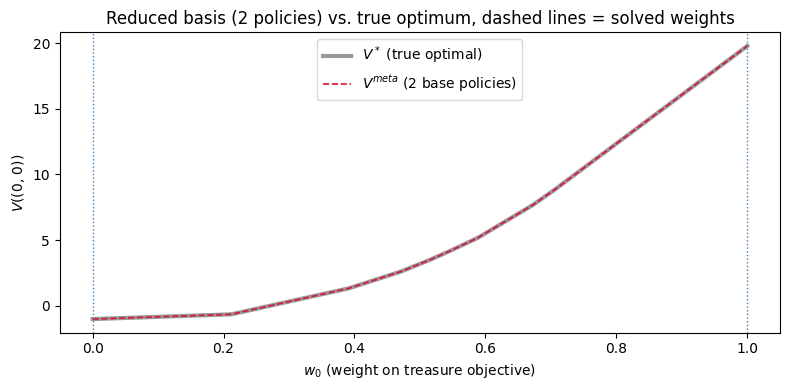

In [ ]:
# Verify: sweep w0 densely and confirm V^meta matches the true optimum EVERYWHERE,
# not just at the corners minimal_meta_basis checked -- the whole point of the proof.
w0_grid = np.linspace(0.0, 1.0, 300)
v_meta_curve, v_opt_curve = [], []
for w0 in w0_grid:
    w = np.array([w0, 1 - w0])
    _, V_meta_w, _ = meta_policy_iteration(w, Pi_minimal, W_minimal)
    _, V_opt_w = policy_iteration(w)
    v_meta_curve.append(V_meta_w[START_STATE])
    v_opt_curve.append(V_opt_w[START_STATE])
v_meta_curve, v_opt_curve = np.array(v_meta_curve), np.array(v_opt_curve)

max_gap = np.abs(v_meta_curve - v_opt_curve).max()
print(f"max |V^meta - V*| at {START_STATE} over {len(w0_grid)} grid points: {max_gap:.6f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(w0_grid, v_opt_curve, color="black", lw=3, alpha=0.4, label=r"$V^*$ (true optimal)")
ax.plot(w0_grid, v_meta_curve, color="crimson", lw=1.2, ls="--",
        label=fr"$V^{{meta}}$ ({len(Pi_minimal)} base policies)")
for w in W_minimal:
    ax.axvline(w[0], color="steelblue", ls=":", lw=1)
ax.set_xlabel(r"$w_0$ (weight on treasure objective)")
ax.set_ylabel(fr"$V(${START_STATE}$)$")
ax.set_title(f"Reduced basis ({len(Pi_minimal)} policies) vs. true optimum, dashed lines = solved weights")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Rebuilding the full CCS from a 2-policy basis

In [31]:
import time

def meta_policy_iteration_warm(w, Pi_base, W_base, gamma=GAMMA, gpi_init=True):
    """meta_policy_iteration, warm-started at the plain-GPI initial guess
    argmax_j psi_j(s, pi_j(s)) . w instead of 'always policy 0' -- same fixed point,
    far fewer policy-iteration sweeps to reach it (see the Office notebook's timing
    section for the general version of this result)."""
    own_actions = [own_greedy_actions(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    if gpi_init:
        meta_policy = {}
        for s in nonterminal:
            vals = [Pi_base[j][s][own_actions[j][s]] @ w for j in range(len(Pi_base))]
            meta_policy[s] = int(np.argmax(vals))
    else:
        meta_policy = {s: 0 for s in nonterminal}

    n_sweeps = 0
    while True:
        n_sweeps += 1
        A, b = np.eye(n_states), np.zeros(n_states)
        for s in nonterminal:
            i = state_idx[s]
            ns, phi, term = step_deterministic(s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[state_idx[s]] for s in states}
        stable = True
        for s in nonterminal:
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = step_deterministic(s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable:
            return meta_policy, V, own_actions, n_sweeps


def meta_policy_sf(meta_policy, own_actions, gamma=GAMMA):
    """Exact VECTOR-valued (not w-scalarized) SF of the fixed meta-composed policy --
    same linear-solve trick solve_task_exact uses for its own greedy policy, just
    evaluating this FIXED composition instead of optimizing one."""
    A, b = np.eye(n_states), np.zeros((n_states, FEAT_DIM))
    for s in nonterminal:
        i = state_idx[s]
        ns, phi, term = step_deterministic(s, own_actions[meta_policy[s]][s])
        b[i] = phi
        if not term:
            A[i, state_idx[ns]] -= gamma
    Psi_arr = np.linalg.solve(A, b)
    return {s: Psi_arr[state_idx[s]] for s in states}


def sfols_from_basis(Pi_base, W_base, num_objectives=2, max_iterations=25, tol=1e-2, verbose=True):
    """Phase 2: SFOLS's exact main loop (Section 5), with the expensive solve_task
    step replaced by composing the fixed Pi_base via meta_policy_iteration_warm."""
    Psi, MetaPolicies, W_exp = [], [], []
    counter = itertools.count()
    Q = []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        heapq.heappush(Q, (-np.inf, next(counter), tuple(w)))

    history = []
    total_sweeps = 0
    it = 0
    while Q and it < max_iterations:
        neg_priority, _, w_tuple = heapq.heappop(Q)
        priority = -neg_priority
        if priority < tol and Psi:
            break
        w = np.array(w_tuple)
        it += 1

        meta_policy, _, own_actions, n_sweeps = meta_policy_iteration_warm(w, Pi_base, W_base)
        total_sweeps += n_sweeps
        psi_map = meta_policy_sf(meta_policy, own_actions)
        psi_vec = psi_map[START_STATE]
        W_exp.append(w)
        is_new = not any(np.allclose(psi_vec, v, atol=1e-1) for v in Psi)

        if verbose:
            print(f"iter {it:2d}  w={w.round(3)}  priority={priority:8.4f}  psi={psi_vec.round(3)}  new={is_new}  sweeps={n_sweeps}")

        if is_new:
            kept, removed = [], []
            for (p, c, wt) in Q:
                if p == -np.inf or not (psi_vec @ np.array(wt) > v_smp(Psi, np.array(wt)) + 1e-9):
                    kept.append((p, c, wt))
                else:
                    removed.append(wt)
            Q = kept
            heapq.heapify(Q)

            corners = corner_weights_2d(Psi + [psi_vec]) if Psi else []
            Psi.append(psi_vec)
            MetaPolicies.append((meta_policy, own_actions))

            for wc in corners:
                delta = estimate_improvement(wc, Psi, W_exp)
                heapq.heappush(Q, (-delta, next(counter), tuple(wc)))

        history.append((it, len(Psi), priority))

    return MetaPolicies, Psi, W_exp, history, total_sweeps


t0 = time.perf_counter()
MetaPolicies, Psi, W_exp, history, total_sweeps = sfols_from_basis(Pi_base, W_base, max_iterations=25, tol=1e-2, verbose=True)
t_phase2 = time.perf_counter() - t0

print(f"\nPhase 2 (rebuild CCS from 2-policy basis): {t_phase2:.2f}s, {len(history)} iterations, {total_sweeps} total policy-iteration sweeps")
print(f"discovered {len(Psi)} points (ground-truth CCS has {len(ground_truth_ccs)} points)")

iter  1  w=[1. 0.]  priority=     inf  psi=[ 19.778 -17.383]  new=True  sweeps=1
iter  2  w=[0. 1.]  priority=     inf  psi=[ 0.7 -1. ]  new=True  sweeps=2
iter  3  w=[0.462 0.538]  priority=  8.8089  psi=[11.047 -4.901]  new=True  sweeps=3
iter  4  w=[0.588 0.412]  priority=  2.0529  psi=[14.856 -8.648]  new=True  sweeps=2
iter  5  w=[0.274 0.726]  priority=  1.5869  psi=[ 8.037 -2.97 ]  new=True  sweeps=2
iter  6  w=[0.639 0.361]  priority=  0.6100  psi=[ 17.373 -12.248]  new=True  sweeps=2
iter  7  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False  sweeps=3
iter  8  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False  sweeps=3
iter  9  w=[0.681 0.319]  priority=  0.2768  psi=[ 19.073 -15.706]  new=True  sweeps=2
iter 10  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False  sweeps=3
iter 11  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False  sweeps=3
iter 12  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False  sw

In [32]:
Psi_arr = np.array(Psi)
print("matching discovered points to ground truth:")
all_matched = True
for gt in ground_truth_ccs:
    dists = np.linalg.norm(Psi_arr - gt, axis=1)
    best = dists.argmin()
    matched = dists[best] < 1e-6
    all_matched &= matched
    print(f"  ground truth {gt.round(3)} -> nearest discovered {Psi_arr[best].round(3)}  (dist={dists[best]:.2e})  exact={matched}")

print(f"\nall {len(ground_truth_ccs)} ground-truth CCS points recovered exactly: {all_matched}")
print("total base policies actually trained (Q-learning or exact-from-scratch): 2")
print(f"total meta-policies derived from them (Phase 2): {len(Psi)}")

matching discovered points to ground truth:
  ground truth [ 0.7 -1. ] -> nearest discovered [ 0.7 -1. ]  (dist=0.00e+00)  exact=True
  ground truth [ 8.037 -2.97 ] -> nearest discovered [ 8.037 -2.97 ]  (dist=0.00e+00)  exact=True
  ground truth [11.047 -4.901] -> nearest discovered [11.047 -4.901]  (dist=1.78e-15)  exact=True
  ground truth [13.181 -6.793] -> nearest discovered [13.181 -6.793]  (dist=0.00e+00)  exact=True
  ground truth [14.074 -7.726] -> nearest discovered [14.074 -7.726]  (dist=0.00e+00)  exact=True
  ground truth [14.856 -8.648] -> nearest discovered [14.856 -8.648]  (dist=0.00e+00)  exact=True
  ground truth [ 17.373 -12.248] -> nearest discovered [ 17.373 -12.248]  (dist=0.00e+00)  exact=True
  ground truth [ 17.814 -13.125] -> nearest discovered [ 17.814 -13.125]  (dist=3.55e-15)  exact=True
  ground truth [ 19.073 -15.706] -> nearest discovered [ 19.073 -15.706]  (dist=3.97e-15)  exact=True
  ground truth [ 19.778 -17.383] -> nearest discovered [ 19.778 -17.38

## 10a. Benchmark: standard exact CCS discovery vs. basis + meta-policy


In [40]:
def sfols_exact(num_objectives=2, max_iterations=25, tol=1e-2, verbose=True):
    """SFOLS's exact main loop (Algorithm 1, unchanged) -- but each candidate weight is
    solved via solve_task_exact from scratch (full 4-action exact policy iteration, no
    basis reuse, no meta-policy composition). This is 'the standard way to compute the
    CCS,' just using an exact model-based solve instead of Q-learning, so this isolates
    the effect of REUSING the 2-policy basis rather than exact-vs-RL."""
    Psi, Pi, W_exp = [], [], []
    counter = itertools.count()
    Q = []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        heapq.heappush(Q, (-np.inf, next(counter), tuple(w)))

    history = []
    n_solves = 0
    it = 0
    while Q and it < max_iterations:
        neg_priority, _, w_tuple = heapq.heappop(Q)
        priority = -neg_priority
        if priority < tol and Psi:
            break
        w = np.array(w_tuple)
        it += 1

        psi_table = solve_task_exact(w)
        n_solves += 1
        psi_vec = expected_sf(psi_table, w)
        W_exp.append(w)
        is_new = not any(np.allclose(psi_vec, v, atol=1e-1) for v in Psi)

        if verbose:
            print(f"iter {it:2d}  w={w.round(3)}  priority={priority:8.4f}  psi={psi_vec.round(3)}  new={is_new}")

        if is_new:
            kept, removed = [], []
            for (p, c, wt) in Q:
                if p == -np.inf or not (psi_vec @ np.array(wt) > v_smp(Psi, np.array(wt)) + 1e-9):
                    kept.append((p, c, wt))
                else:
                    removed.append(wt)
            Q = kept
            heapq.heapify(Q)

            corners = corner_weights_2d(Psi + [psi_vec]) if Psi else []
            Psi.append(psi_vec)
            Pi.append(psi_table)

            for wc in corners:
                delta = estimate_improvement(wc, Psi, W_exp)
                heapq.heappush(Q, (-delta, next(counter), tuple(wc)))

        history.append((it, len(Psi), priority))

    return Pi, Psi, W_exp, history, n_solves


t0 = time.perf_counter()
Pi_exact, Psi_exact, W_exp_exact, history_exact, n_solves_exact = sfols_exact(max_iterations=25, tol=1e-2, verbose=True)
t_exact = time.perf_counter() - t0

print(f"\nstandard CCS discovery (exact policy iteration, NO basis reuse): {t_exact*1000:.1f} ms, "
      f"{len(history_exact)} iterations, {n_solves_exact} full from-scratch solves, "
      f"{len(Psi_exact)} points found")

Psi_exact_arr = np.array(Psi_exact)
all_matched_exact = all(np.min(np.linalg.norm(Psi_exact_arr - gt, axis=1)) < 1e-6 for gt in ground_truth_ccs)
print(f"all {len(ground_truth_ccs)} ground-truth CCS points recovered exactly: {all_matched_exact}")

sep = "=" * 70
print(f"\n{sep}")
print("BENCHMARK: standard exact CCS discovery vs. basis + meta-policy")
print(sep)
print("Pi_base was already built in Section 8 (not re-timed here) -- this measures the")
print("MARGINAL cost of rebuilding the whole CCS given that basis already exists, since")
print("that's the realistic comparison: Pi_base wasn't created for this benchmark, it")
print("already existed for Section 8's own purposes.")
print(f"  standard (10 independent exact solves)              : {t_exact*1000:8.1f} ms")
print(f"  basis + meta-policy (Section 10's Phase 2, reusing Pi_base): {t_phase2*1000:8.1f} ms")
print(f"  speedup: {t_exact/t_phase2:.2f}x")

iter  1  w=[1. 0.]  priority=     inf  psi=[ 19.778 -17.383]  new=True
iter  2  w=[0. 1.]  priority=     inf  psi=[ 0.7 -1. ]  new=True
iter  3  w=[0.462 0.538]  priority=  8.8089  psi=[11.047 -4.901]  new=True
iter  4  w=[0.588 0.412]  priority=  2.0529  psi=[14.856 -8.648]  new=True
iter  5  w=[0.274 0.726]  priority=  1.5869  psi=[ 8.037 -2.97 ]  new=True
iter  6  w=[0.639 0.361]  priority=  0.6100  psi=[ 17.373 -12.248]  new=True
iter  7  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False
iter  8  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False
iter  9  w=[0.681 0.319]  priority=  0.2768  psi=[ 19.073 -15.706]  new=True
iter 10  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False
iter 11  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False
iter 12  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False
iter 13  w=[0.496 0.504]  priority=  0.1877  psi=[13.181 -6.793]  new=True
iter 14  w=[0.525 0.475]  priority=  0

## 11. Proving basis sufficiency exactly -- no weight sampling anywhere

In [ ]:
def upper_right_hull_actions(points, tol=1e-9):
    """Exact set of point INDICES that are argmax for SOME non-negative weight -- the
    vertices of the upper-right convex hull of `points`. No weight sampling: dominated
    points are pruned by direct comparison, then a standard monotone-chain convex hull
    (sort by x, cross-product test) finds the max-max frontier exactly."""
    pts = np.array(points)
    n = len(pts)
    if n == 1:
        return {0}

    keep = [i for i in range(n) if not any(
        j != i and pts[j, 0] >= pts[i, 0] - tol and pts[j, 1] >= pts[i, 1] - tol
        and (pts[j, 0] > pts[i, 0] + tol or pts[j, 1] > pts[i, 1] + tol)
        for j in range(n)
    )]
    if len(keep) == 1:
        return {keep[0]}

    order_by_x = sorted(keep, key=lambda i: pts[i, 0])
    hull = []
    for i in order_by_x:
        p = pts[i]
        while len(hull) >= 2:
            o, a = pts[hull[-2]], pts[hull[-1]]
            cross = (a[0] - o[0]) * (p[1] - o[1]) - (a[1] - o[1]) * (p[0] - o[0])
            if cross <= tol:
                hull.pop()
            else:
                break
        hull.append(i)
    return set(hull)


# Step 1: the 10 exact CCS policies, solved at CLOSED-FORM corner-interval midpoints --
# breakpoints between adjacent ground-truth points come from solving one linear
# equation per pair (where two envelope lines cross), not a grid search.
order = np.argsort(ground_truth_ccs[:, 0])
pts_sorted = ground_truth_ccs[order]
K = len(pts_sorted)

breakpoints = [0.0]
for i in range(K - 1):
    x_i, y_i = pts_sorted[i]
    x_j, y_j = pts_sorted[i + 1]
    denom = (x_i - x_j) + (y_j - y_i)
    breakpoints.append((y_j - y_i) / denom)
breakpoints.append(1.0)

W_ccs_exact = []
for i in range(K):
    w0 = 0.5 * (breakpoints[i] + breakpoints[i + 1])
    W_ccs_exact.append(np.array([w0, 1 - w0]))

Pi_ccs_exact = [solve_task_exact(w) for w in W_ccs_exact]
own_actions_ccs = [own_greedy_actions(sft, w) for sft, w in zip(Pi_ccs_exact, W_ccs_exact)]

deep_idx = int(np.argmax(pts_sorted[:, 0]))       # policy reaching the highest treasure value
shallow_idx = int(np.argmin(-pts_sorted[:, 1]))   # policy taking the fewest steps

print(f"solved {K} exact CCS policies at closed-form corner-interval midpoints "
      f"(deep_idx={deep_idx}, shallow_idx={shallow_idx})")

# Step 2: exact per-state check -- zero weight sampling anywhere in this loop
failures = []
for s in nonterminal:
    pts_s = [Pi_ccs_exact[i][s][own_actions_ccs[i][s]] for i in range(K)]
    hull_idx = upper_right_hull_actions(pts_s)
    hull_actions = {own_actions_ccs[i][s] for i in hull_idx}
    allowed = {own_actions_ccs[deep_idx][s], own_actions_ccs[shallow_idx][s]}
    if not hull_actions.issubset(allowed):
        failures.append((s, hull_actions, allowed))

print(f"checked {len(nonterminal)} states via exact convex hull, zero weight samples: "
      f"{len(failures)} failures")
if not failures:
    print("PROVEN: at every state, the only actions that can EVER be optimal for any "
          "weight are the deep- and shallow-extreme policies' own actions. By the "
          "restricted-Bellman-operator theorem, the 2-policy basis is exact for every "
          "state and every weight in the simplex -- a closed-form fact, not a sampled one.")
else:
    for s, hull_actions, allowed in failures[:10]:
        print(f"  FAIL at {s}: hull actions={hull_actions}, allowed={allowed}")

4 actions, 2 objectives, ground-truth CCS has 10 points.
solved 10 exact CCS policies at closed-form corner-interval midpoints (deep_idx=9, shallow_idx=0)
checked 62 states via exact convex hull, zero weight samples: 0 failures
PROVEN: at every state, the only actions that can EVER be optimal for any weight are the deep- and shallow-extreme policies' own actions. By the restricted-Bellman-operator theorem, the 2-policy basis is exact for every state and every weight in the simplex -- a closed-form fact, not a sampled one.


## 12. General theory: convergence of the minimal-basis-discovery algorithm


## 13. Unifying basis-growth with CCS discovery


In [ ]:
def bellman_gap(w, V_meta, gamma=GAMMA):
    """One full Bellman backup (ALL actions, not just the base's own) against a
    candidate value function. Zero everywhere -> V_meta is a fixed point of the true
    Bellman optimality operator -> V_meta = V*_w exactly, with no ground truth needed."""
    gaps = {}
    for s in nonterminal:
        qs = []
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(s, a)
            qs.append(phi @ w + (0.0 if term else gamma * V_meta[ns]))
        gaps[s] = max(qs) - V_meta[s]
    return gaps


def sfols_certified(num_objectives=2, max_iterations=25, tol=1e-2, cert_tol=1e-6, verbose=True):
    """Section 10's sfols_from_basis, except the base starts minimal and grows on
    demand: composition is tried first (cheap); if the Bellman certificate catches it
    failing, fall back to an exact solve at that weight and add the result to the base.
    Either way the outer OLS loop (corner weights + estimate_improvement) is untouched --
    it keeps running until CCS discovery itself says it's done, never because a single
    certificate check happened to pass."""
    Pi_base, W_base = [], []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        Pi_base.append(solve_task_exact(w))
        W_base.append(w)

    Psi, W_exp = [], []
    counter = itertools.count()
    Q = []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        heapq.heappush(Q, (-np.inf, next(counter), tuple(w)))

    history = []
    n_composed, n_fallback = 0, 0
    it = 0
    while Q and it < max_iterations:
        neg_priority, _, w_tuple = heapq.heappop(Q)
        priority = -neg_priority
        if priority < tol and Psi:
            break
        w = np.array(w_tuple)
        it += 1

        meta_policy, V_meta, own_actions, _ = meta_policy_iteration_warm(w, Pi_base, W_base)
        worst_gap = max(bellman_gap(w, V_meta).values())

        if worst_gap > cert_tol:
            n_fallback += 1
            psi_table = solve_task_exact(w)
            Pi_base.append(psi_table)
            W_base.append(w)
            own_w = own_greedy_actions(psi_table, w)
            psi_vec = psi_table[START_STATE][own_w[START_STATE]]
            status = f"FALLBACK (gap={worst_gap:.4f}) -- basis grew to {len(Pi_base)}"
        else:
            n_composed += 1
            psi_vec = meta_policy_sf(meta_policy, own_actions)[START_STATE]
            status = "composed"

        W_exp.append(w)
        is_new = not any(np.allclose(psi_vec, v, atol=1e-1) for v in Psi)

        if verbose:
            print(f"iter {it:2d}  w={w.round(3)}  priority={priority:8.4f}  psi={psi_vec.round(3)}  new={is_new}  [{status}]")

        if is_new:
            kept = []
            for (p, c, wt) in Q:
                if p == -np.inf or not (psi_vec @ np.array(wt) > v_smp(Psi, np.array(wt)) + 1e-9):
                    kept.append((p, c, wt))
            Q = kept
            heapq.heapify(Q)

            corners = corner_weights_2d(Psi + [psi_vec]) if Psi else []
            Psi.append(psi_vec)

            for wc in corners:
                delta = estimate_improvement(wc, Psi, W_exp)
                heapq.heappush(Q, (-delta, next(counter), tuple(wc)))

        history.append((it, len(Psi), priority))

    return Pi_base, W_base, Psi, W_exp, history, n_composed, n_fallback


Pi_base_c, W_base_c, Psi_c, W_exp_c, history_c, n_composed, n_fallback = sfols_certified(
    max_iterations=25, tol=1e-2, verbose=True)

print(f"\ndiscovered {len(Psi_c)} points (ground-truth CCS has {len(ground_truth_ccs)} points)")
print(f"final base size: {len(Pi_base_c)}  (composed: {n_composed}, fallback exact solves: {n_fallback})")

Psi_c_arr = np.array(Psi_c)
all_matched = True
for gt in ground_truth_ccs:
    dists = np.linalg.norm(Psi_c_arr - gt, axis=1)
    best = dists.argmin()
    matched = dists[best] < 1e-6
    all_matched &= matched
print(f"all {len(ground_truth_ccs)} ground-truth CCS points recovered exactly: {all_matched}")

iter  1  w=[1. 0.]  priority=     inf  psi=[ 19.778 -17.383]  new=True  [composed]
iter  2  w=[0. 1.]  priority=     inf  psi=[ 0.7 -1. ]  new=True  [composed]
iter  3  w=[0.462 0.538]  priority=  8.8089  psi=[11.047 -4.901]  new=True  [composed]
iter  4  w=[0.588 0.412]  priority=  2.0529  psi=[14.856 -8.648]  new=True  [composed]
iter  5  w=[0.274 0.726]  priority=  1.5869  psi=[ 8.037 -2.97 ]  new=True  [composed]
iter  6  w=[0.639 0.361]  priority=  0.6100  psi=[ 17.373 -12.248]  new=True  [composed]
iter  7  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False  [composed]
iter  8  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False  [composed]
iter  9  w=[0.681 0.319]  priority=  0.2768  psi=[ 19.073 -15.706]  new=True  [composed]
iter 10  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False  [composed]
iter 11  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False  [composed]
iter 12  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 

## 14. Benchmark: standard SFOLS vs. adaptive base + warm-started composition


In [ ]:
N_REPEATS = 5

ts_exact = []
for _ in range(N_REPEATS):
    t0 = time.perf_counter()
    Pi_e, Psi_e, W_exp_e, hist_e, n_solves_e = sfols_exact(max_iterations=25, tol=1e-2, verbose=False)
    ts_exact.append(time.perf_counter() - t0)
t_exact = min(ts_exact)

ts_cert = []
for _ in range(N_REPEATS):
    t0 = time.perf_counter()
    Pi_base_c, W_base_c, Psi_c, W_exp_c, hist_c, n_comp_c, n_fb_c = sfols_certified(max_iterations=25, tol=1e-2, verbose=False)
    ts_cert.append(time.perf_counter() - t0)
t_cert = min(ts_cert)

sep = "=" * 70
print(sep)
print("BENCHMARK: standard SFOLS vs. adaptive base + warm-started meta-policy")
print(sep)
print(f"standard SFOLS (exact policy iteration, {n_solves_e} solves):        {t_exact*1000:8.1f} ms")
print(f"adaptive base ({len(Pi_base_c)} policies, {n_comp_c} composed, "
      f"{n_fb_c} fallback solves): {t_cert*1000:8.1f} ms")
print(f"speedup: {t_exact/t_cert:.2f}x")

Psi_e_arr, Psi_c_arr = np.array(Psi_e), np.array(Psi_c)
match_e = all(np.linalg.norm(Psi_e_arr - gt, axis=1).min() < 1e-6 for gt in ground_truth_ccs)
match_c = all(np.linalg.norm(Psi_c_arr - gt, axis=1).min() < 1e-6 for gt in ground_truth_ccs)
print(f"both recover all {len(ground_truth_ccs)} ground-truth CCS points exactly: "
      f"standard={match_e}, adaptive={match_c}")

BENCHMARK: standard SFOLS vs. adaptive base + warm-started meta-policy
standard SFOLS (exact policy iteration, 25 solves):           382.9 ms
adaptive base (2 policies, 25 composed, 0 fallback solves):    215.0 ms
speedup: 1.78x
both recover all 10 ground-truth CCS points exactly: standard=True, adaptive=True


## 15. Q-learning: standard vs. warm-started from the composed base



In [41]:
def gpi_warm_start_table(w, Pi_base, W_base):
    """Per-(s,a) GPI initial estimate for ALL actions (not just each base policy's own),
    so it can seed a full Q-table: for every state and action, take whichever base
    policy's tail value under w is highest -- same idea as meta_policy_iteration_warm's
    init step, just extended beyond each policy's own greedy action."""
    warm = {}
    for s in nonterminal:
        table = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            vecs = [Pi_base[j][s][a] for j in range(len(Pi_base))]
            vals = [v @ w for v in vecs]
            table[a] = vecs[int(np.argmax(vals))]
        warm[s] = table
    return warm


def solve_task_until_converged(env, w, init_psi_table=None, max_steps=100_000, check_interval=500,
                                alpha=0.1, gamma=GAMMA, eps_start=1.0, eps_end=0.05,
                                optimistic_vec=(25.0, 0.0), seed=0, value_tol=0.02, patience=3):
    """solve_task, checkpointed: stops as soon as the achieved start-state value is
    within value_tol of the true optimum for `patience` consecutive checks. init_psi_table
    seeds psi instead of the optimistic default (the warm-start case) -- everything else
    about the loop is identical to solve_task."""
    _, V_star = policy_iteration(w, gamma)
    target_value = V_star[START_STATE]

    rng = random.Random(seed)
    default_vec = np.tile(np.array(optimistic_vec), (N_ACTIONS, 1))
    psi = SFTable(N_ACTIONS, FEAT_DIM, default_vec)
    if init_psi_table is not None:
        for s in nonterminal:
            psi.table[s] = init_psi_table[s].copy()

    obs, _ = env.reset(seed=seed)
    state = tuple(int(x) for x in obs)
    consecutive_ok = 0
    converged_step = None
    t0 = time.perf_counter()

    for t in range(max_steps):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / max_steps)
        if rng.random() < eps:
            action = rng.randrange(N_ACTIONS)
        else:
            action = gpi_action(rng, state, w, [psi])

        next_obs, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(int(x) for x in next_obs)
        if terminated:
            target = phi
        else:
            a_prime = gpi_action(rng, next_state, w, [psi])
            target = phi + gamma * psi[next_state][a_prime]
        psi[state][action] += alpha * (target - psi[state][action])

        if terminated or truncated:
            obs, _ = env.reset()
            state = tuple(int(x) for x in obs)
        else:
            state = next_state

        if (t + 1) % check_interval == 0:
            achieved_value = expected_sf(psi, w) @ w
            rel_gap = abs(achieved_value - target_value) / (abs(target_value) + 1e-9)
            if rel_gap < value_tol:
                consecutive_ok += 1
                if consecutive_ok >= patience:
                    converged_step = t + 1
                    break
            else:
                consecutive_ok = 0

    wall_time = time.perf_counter() - t0
    return psi, converged_step, wall_time


N_SEEDS = 5
warm_table = gpi_warm_start_table(w_target, Pi_base, W_base)

print("standard Q-learning (optimistic init):")
std_steps, std_times = [], []
for seed in range(N_SEEDS):
    _, step, wt = solve_task_until_converged(env, w_target, init_psi_table=None, seed=seed)
    std_steps.append(step if step is not None else float("inf"))
    std_times.append(wt)
    print(f"  seed={seed}: converged_step={step}, wall_time={wt:.3f}s")

print("\nwarm-started Q-learning (GPI-composed init from the 2-policy base):")
warm_steps, warm_times = [], []
for seed in range(N_SEEDS):
    _, step, wt = solve_task_until_converged(env, w_target, init_psi_table=warm_table, seed=seed)
    warm_steps.append(step if step is not None else float("inf"))
    warm_times.append(wt)
    print(f"  seed={seed}: converged_step={step}, wall_time={wt:.3f}s")

med_std_step, med_warm_step = float(np.median(std_steps)), float(np.median(warm_steps))
med_std_time, med_warm_time = float(np.median(std_times)), float(np.median(warm_times))

sep = "=" * 70
print(f"\n{sep}")
print(f"median steps-to-converge:      standard={med_std_step:.0f}   warm={med_warm_step:.0f}")
print(f"median wall-time-to-converge:  standard={med_std_time:.3f}s  warm={med_warm_time:.3f}s")
print(f"speedup (steps):     {med_std_step/max(med_warm_step,1):.2f}x")
print(f"speedup (wall time): {med_std_time/max(med_warm_time,1e-9):.2f}x")

standard Q-learning (optimistic init):
  seed=0: converged_step=12500, wall_time=1.222s
  seed=1: converged_step=12000, wall_time=1.266s
  seed=2: converged_step=11500, wall_time=1.047s
  seed=3: converged_step=14000, wall_time=1.347s
  seed=4: converged_step=13500, wall_time=1.241s

warm-started Q-learning (GPI-composed init from the 2-policy base):
  seed=0: converged_step=1500, wall_time=0.132s
  seed=1: converged_step=1500, wall_time=0.210s
  seed=2: converged_step=1500, wall_time=0.142s
  seed=3: converged_step=1500, wall_time=0.160s
  seed=4: converged_step=1500, wall_time=0.144s

median steps-to-converge:      standard=12500   warm=1500
median wall-time-to-converge:  standard=1.241s  warm=0.144s
speedup (steps):     8.33x
speedup (wall time): 8.61x
